# Eksplorasi Mendalam Algoritma Random Forest
## Klasifikasi Penyakit Parkinson (*Parkinson's Disease Classification*)

**Algoritma:** `RandomForestClassifier` (Scikit-learn) &nbsp;|&nbsp; **Dataset:** `parkinsons_disease_data.csv` (2.105 baris × 35 kolom)

Notebook ini mengeksplorasi satu algoritma — **Random Forest** — untuk mengklasifikasikan pasien ke dalam **dua kelas** (klasifikasi biner):

0. Tidak Terdiagnosis Parkinson
1. Terdiagnosis Parkinson

Kolom `Diagnosis` adalah **label (`y`)**. Dari 34 kolom lainnya, kolom identitas/konstan (`PatientID`, `DoctorInCharge`) diperiksa dahulu dan dibuang bila tidak bernilai prediktif, sedangkan sisanya menjadi **fitur (`X`)**.

**Alur kerja:** EDA → pemeriksaan kualitas data & risiko *target leakage* → preprocessing (`Pipeline` + `ColumnTransformer`) → split 80:20 stratified → Skenario A (`n_estimators`) → Skenario B (`max_depth`) → feature importance → evaluasi akhir → business insight → penyimpanan model.

## 2. Tujuan Penelitian

1. Membangun model Random Forest untuk mengklasifikasikan pasien menjadi terdiagnosis Parkinson atau tidak terdiagnosis Parkinson.
2. Menganalisis pengaruh **jumlah pohon** (`n_estimators`) terhadap akurasi training dan testing (Skenario A).
3. Menganalisis pengaruh **kedalaman pohon** (`max_depth`) terhadap kompleksitas model serta indikasi *underfitting/overfitting* (Skenario B).
4. Mengidentifikasi fitur yang paling penting secara prediktif melalui *feature importance*.
5. Mengevaluasi model secara menyeluruh dengan memperhatikan **ketidakseimbangan kelas** (bukan hanya *accuracy*).
6. Mendokumentasikan risiko *target leakage* (terutama pada fitur pemeriksaan klinis seperti `UPDRS`) dan keterbatasan interpretasi hasil.
7. Menyimpan *pipeline* (preprocessing + model) agar dapat digunakan kembali untuk memprediksi data baru.

## 3. Import Library

Semua *library* yang dibutuhkan diimpor di awal. `RANDOM_STATE = 42` dipakai di seluruh proses (split data & model) agar hasil **dapat direproduksi**. Path dibuat **relatif** terhadap folder kerja dan dapat diubah lewat variabel `DATA_PATH_OVERRIDE`, sehingga notebook dapat dijalankan di komputer lain (termasuk Windows). Bila file CSV tidak ditemukan, notebook menampilkan pesan error yang jelas beserta lokasi yang sudah dicari.

In [1]:
import json
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, log_loss,
                             precision_recall_fscore_support, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Tema visual yang konsisten untuk semua grafik
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 11, "legend.fontsize": 10})

RANDOM_STATE = 42

# ---------------------------------------------------------------------------------------
# Lokasi file. Ubah DATA_PATH_OVERRIDE bila CSV berada di tempat lain, contoh (Windows):
#   DATA_PATH_OVERRIDE = r"C:\Users\NamaAnda\Documents\parkinsons_disease_data.csv"
# ---------------------------------------------------------------------------------------
DATA_PATH_OVERRIDE = None
DATASET_NAMES = ["parkinsons_disease_data.csv", "parkinsons_disease_data(1).csv"]

# Path relatif: berfungsi baik jika notebook dijalankan dari folder notebook/ maupun dari root proyek
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
MODEL_DIR = BASE_DIR / "model"


def find_dataset():
    # Mencari file CSV di beberapa lokasi umum dan memberi pesan error yang jelas bila tidak ada.
    if DATA_PATH_OVERRIDE:
        candidates = [Path(DATA_PATH_OVERRIDE)]
    else:
        candidates = [folder / name for folder in (BASE_DIR / "data", BASE_DIR, Path.cwd())
                      for name in DATASET_NAMES]
    for path in candidates:
        if path.is_file():
            return path
    searched = "\n  - ".join(str(p) for p in candidates)
    raise FileNotFoundError("File dataset Parkinson tidak ditemukan. Lokasi yang sudah dicari:\n  - "
                            f"{searched}\nLetakkan CSV di salah satu lokasi tersebut atau isi DATA_PATH_OVERRIDE.")


DATA_PATH = find_dataset()

TARGET = "Diagnosis"
# Urutan kelas + nama kelas + label singkat untuk grafik
CLASS_ORDER = [0, 1]
CLASS_NAMES = {0: "Tidak Terdiagnosis Parkinson", 1: "Terdiagnosis Parkinson"}
SHORT_LABEL = {0: "Tidak\nParkinson", 1: "Parkinson"}
CLASS_COLORS = {0: "#4c72b0", 1: "#dd8452"}


def flat(label):
    # Ubah label grafik bertingkat (ada \n) menjadi satu baris untuk tabel.
    return label.replace("\n", " ")


print("Versi scikit-learn :", sklearn.__version__)
print("Folder proyek      :", BASE_DIR.name)
print("Dataset ditemukan  :", DATA_PATH.exists(), "->", DATA_PATH.name)

Versi scikit-learn : 1.7.2
Folder proyek      : NeuroGuard-AI
Dataset ditemukan  : True -> parkinsons_disease_data.csv


## 4. Load Dataset

Dataset dibaca dengan Pandas dari `parkinsons_disease_data.csv`. Dataset asli **tidak diubah maupun ditimpa**; seluruh transformasi dilakukan pada salinan di memori. Tidak ada data sintetis tambahan yang dibuat dalam notebook ini.

In [2]:
df = pd.read_csv(DATA_PATH)

print(f"Ukuran dataset : {df.shape[0]:,} baris x {df.shape[1]} kolom\n")
print("Nama kolom:")
print(list(df.columns))

print("\nTipe data tiap kolom:")
display(df.dtypes.astype(str).rename("dtype").to_frame())

print("Lima baris pertama:")
display(df.head())

# Validasi: struktur data harus sesuai informasi yang diharapkan
assert df.shape == (2105, 35), "Ukuran dataset tidak sesuai dengan yang diharapkan (2105 x 35)"
assert TARGET in df.columns, "Kolom target 'Diagnosis' tidak ditemukan"
assert set(df[TARGET].unique()) == set(CLASS_ORDER), "Label Diagnosis harus tepat berisi kelas 0 dan 1"
print("\nStruktur dataset dan label Diagnosis sesuai dengan yang diharapkan (klasifikasi biner: 0 dan 1).")

Ukuran dataset : 2,105 baris x 35 kolom

Nama kolom:
['PatientID', 'Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'FamilyHistoryParkinsons', 'TraumaticBrainInjury', 'Hypertension', 'Diabetes', 'Depression', 'Stroke', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'UPDRS', 'MoCA', 'FunctionalAssessment', 'Tremor', 'Rigidity', 'Bradykinesia', 'PosturalInstability', 'SpeechProblems', 'SleepDisorders', 'Constipation', 'Diagnosis', 'DoctorInCharge']

Tipe data tiap kolom:


,dtype
PatientID,int64
Age,int64
Gender,int64
Ethnicity,int64
EducationLevel,int64
BMI,float64
Smoking,int64
AlcoholConsumption,float64
PhysicalActivity,float64
DietQuality,float64


Lima baris pertama:


,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryParkinsons,TraumaticBrainInjury,Hypertension,Diabetes,Depression,Stroke,SystolicBP,DiastolicBP,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,UPDRS,MoCA,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation,Diagnosis,DoctorInCharge
0,3058,85,0,3,1,19.619878,0,5.108241,1.380660,3.893969,9.283194,0,0,0,0,0,0,129,60,222.842278,148.125623,37.867776,337.307114,6.458713,29.181289,1.572427,1,0,0,0,0,0,0,0,DrXXXConfid
1,3059,75,0,0,2,16.247339,1,6.027648,8.409804,8.513428,5.602470,0,0,0,0,0,0,163,76,210.501133,153.756463,77.228117,264.635521,37.306703,12.332639,4.787551,0,1,0,1,0,1,0,1,DrXXXConfid
2,3060,70,1,0,0,15.368239,0,2.242135,0.213275,6.498805,9.929824,0,0,0,1,0,0,113,93,287.387996,118.702600,85.588304,395.662649,67.838170,29.927783,2.130686,1,0,0,0,1,0,1,1,DrXXXConfid
3,3061,52,0,0,0,15.454557,0,5.997788,1.375045,6.715033,4.196189,0,0,0,0,0,0,146,78,280.339546,136.299186,51.869626,362.189688,52.964696,21.304268,3.391288,1,1,1,0,0,0,1,1,DrXXXConfid
4,3062,87,0,0,1,18.616042,0,9.775243,1.188607,4.657572,9.363925,0,0,0,0,0,0,115,94,284.014151,108.449452,25.069418,149.956586,21.804880,8.336364,3.200969,0,0,0,1,0,1,0,0,DrXXXConfid



Struktur dataset dan label Diagnosis sesuai dengan yang diharapkan (klasifikasi biner: 0 dan 1).


## 5. Exploratory Data Analysis (EDA)

Tujuan EDA: memahami sebaran nilai fitur dan melihat apakah ada pola yang membedakan kedua kelas secara kasar. Perhatikan bahwa banyak kolom bertipe **bilangan bulat** (`int64`) padahal maknanya **kategori** atau **penanda biner** (mis. `Gender`, `Ethnicity`, `EducationLevel`, `Tremor`, `Rigidity`). Kolom-kolom ini bukan fitur numerik kontinu, sehingga akan diperlakukan sebagai fitur kategorikal pada bagian preprocessing. Sebaliknya `Age`, `SystolicBP`, dan `DiastolicBP` meskipun bilangan bulat tetap merupakan besaran kontinu/terurut.

Karena `PatientID` hanyalah pengenal dan `DoctorInCharge` (lihat hasil di bawah) tidak informatif, keduanya tidak dimasukkan ke statistik fitur.

In [3]:
# Pengelompokan kolom berdasarkan MAKNA (bukan sekadar tipe data)
id_cols = ["PatientID", "DoctorInCharge"]
nominal_cols = ["Gender", "Ethnicity", "EducationLevel"]            # kode kategori (bukan besaran)
binary_cols = ["Smoking", "FamilyHistoryParkinsons", "TraumaticBrainInjury", "Hypertension", "Diabetes",
               "Depression", "Stroke", "Tremor", "Rigidity", "Bradykinesia", "PosturalInstability",
               "SpeechProblems", "SleepDisorders", "Constipation"]   # penanda ada(1)/tidak ada(0)
continuous_cols = [c for c in df.columns if c not in id_cols + nominal_cols + binary_cols + [TARGET]]

# Validasi: setiap kolom biner memang hanya berisi {0, 1}; kolom nominal berisi sedikit kode unik
for c in binary_cols:
    assert set(df[c].unique()) <= {0, 1}, f"{c} bukan kolom biner 0/1"
print("Kolom biner (nilai {0,1})      :", len(binary_cols))
print("Kolom nominal (kode kategori)  :", {c: sorted(df[c].unique().tolist()) for c in nominal_cols})
print("Kolom kontinu/terurut          :", len(continuous_cols), "->", continuous_cols)

# Karakteristik kolom identitas
print(f"\nPatientID : {df['PatientID'].nunique()} nilai unik dari {len(df)} baris | rentang {df['PatientID'].min()}–{df['PatientID'].max()}")
print(f"DoctorInCharge : {df['DoctorInCharge'].nunique()} nilai unik -> {df['DoctorInCharge'].unique().tolist()}")

# Statistik deskriptif fitur numerik kontinu
print("\nStatistik deskriptif fitur numerik kontinu:")
display(df[continuous_cols].describe().T.round(3))

# Distribusi fitur kategorikal / biner (jumlah per nilai)
print("Distribusi fitur kategorikal dan biner:")
cat_dist = pd.DataFrame({c: df[c].value_counts().sort_index() for c in nominal_cols + binary_cols}).T
cat_dist.columns = [f"nilai {c}" for c in cat_dist.columns]
cat_dist["proporsi nilai 1 (%)"] = (df[nominal_cols + binary_cols].eq(1).mean() * 100).round(1).values
display(cat_dist.fillna(0).astype({c: int for c in cat_dist.columns if c.startswith("nilai")}))

Kolom biner (nilai {0,1})      : 14
Kolom nominal (kode kategori)  : {'Gender': [0, 1], 'Ethnicity': [0, 1, 2, 3], 'EducationLevel': [0, 1, 2, 3]}
Kolom kontinu/terurut          : 15 -> ['Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'UPDRS', 'MoCA', 'FunctionalAssessment']

PatientID : 2105 nilai unik dari 2105 baris | rentang 3058–5162
DoctorInCharge : 1 nilai unik -> ['DrXXXConfid']

Statistik deskriptif fitur numerik kontinu:


,count,mean,std,min,25%,50%,75%,max
Age,2105.0,69.602,11.595,50.000,60.000,70.000,80.000,89.000
BMI,2105.0,27.209,7.208,15.008,20.782,27.185,33.462,40.000
AlcoholConsumption,2105.0,10.040,5.687,0.002,5.150,10.070,14.830,19.989
PhysicalActivity,2105.0,5.017,2.891,0.004,2.456,5.032,7.513,9.995
DietQuality,2105.0,4.913,2.872,0.000,2.479,4.825,7.381,9.996
SleepQuality,2105.0,6.997,1.753,4.000,5.489,6.930,8.559,10.000
SystolicBP,2105.0,133.720,26.502,90.000,110.000,133.000,157.000,179.000
DiastolicBP,2105.0,90.250,17.061,60.000,75.000,91.000,105.000,119.000
CholesterolTotal,2105.0,226.861,43.589,150.063,189.385,228.528,264.608,299.963
CholesterolLDL,2105.0,126.148,43.407,50.023,88.842,126.885,163.913,199.986


Distribusi fitur kategorikal dan biner:


,nilai 0,nilai 1,nilai 2,nilai 3,proporsi nilai 1 (%)
Gender,1068,1037,0,0,49.3
Ethnicity,1270,425,197,213,20.2
EducationLevel,388,840,656,221,39.9
Smoking,1481,624,0,0,29.6
FamilyHistoryParkinsons,1798,307,0,0,14.6
TraumaticBrainInjury,1881,224,0,0,10.6
Hypertension,1798,307,0,0,14.6
Diabetes,1793,312,0,0,14.8
Depression,1673,432,0,0,20.5
Stroke,2002,103,0,0,4.9


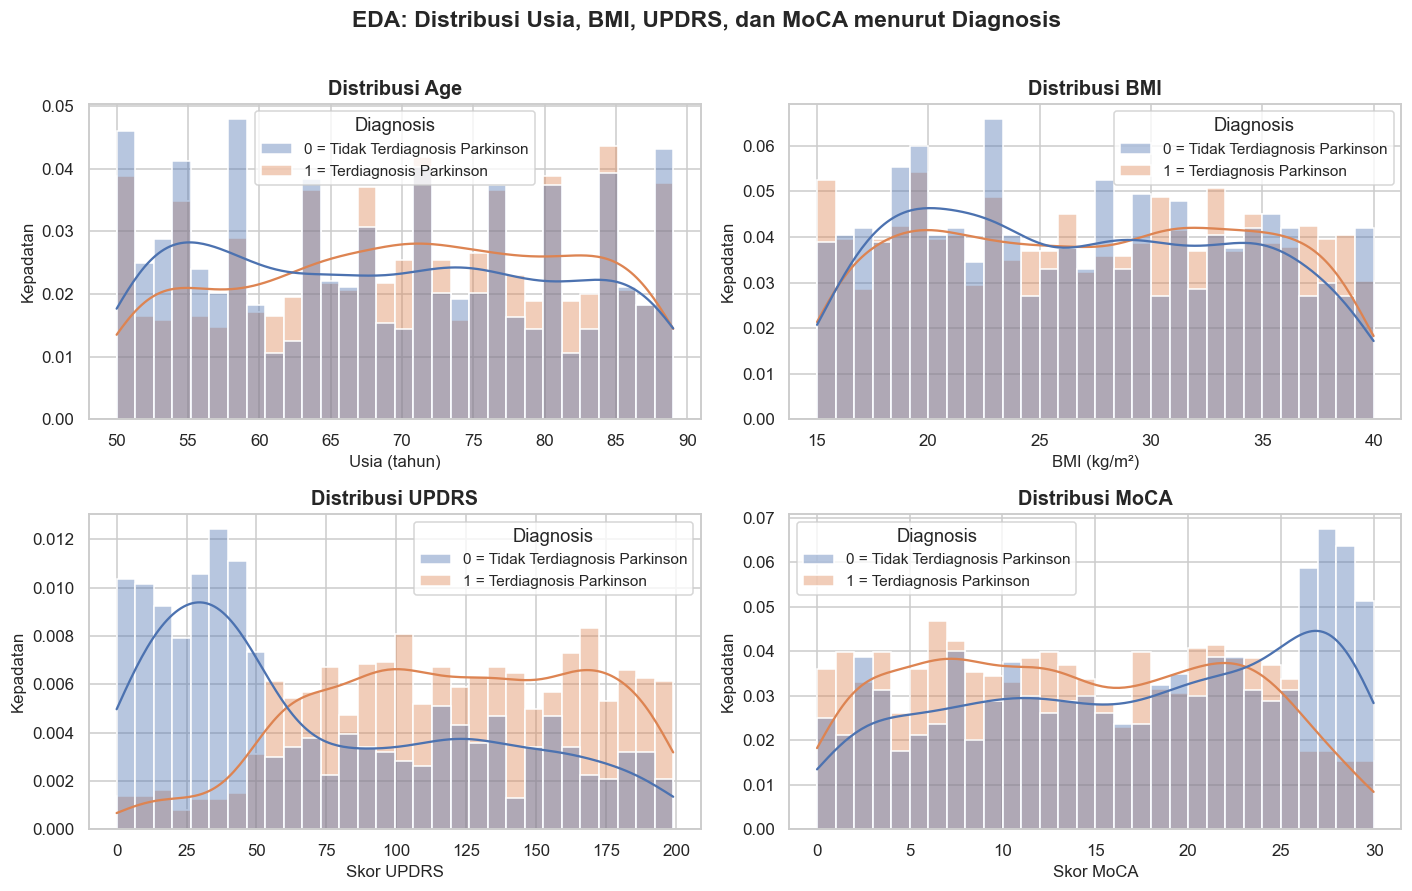

,mean,median,std,min,max
Age,69.60,70.00,11.59,50.00,89.00
BMI,27.21,27.18,7.21,15.01,40.00
UPDRS,101.42,102.56,56.59,0.03,198.95
MoCA,15.09,14.96,8.64,0.02,29.97


In [4]:
# Distribusi usia, BMI, UPDRS, dan MoCA (histogram + KDE), dipisah menurut kelas Diagnosis
dist_cols = [("Age", "Usia (tahun)"), ("BMI", "BMI (kg/m²)"),
             ("UPDRS", "Skor UPDRS"), ("MoCA", "Skor MoCA")]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, xlabel) in zip(axes.ravel(), dist_cols):
    sns.histplot(data=df, x=col, hue=TARGET, palette=CLASS_COLORS, kde=True, bins=30,
                 stat="density", common_norm=False, alpha=0.40, ax=ax)
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Kepadatan")
    leg = ax.get_legend()
    if leg is not None:
        leg.set_title("Diagnosis")
        for t in leg.get_texts():                  # baca label asli (0/1) agar pemetaan nama kelas selalu benar
            k = int(float(t.get_text()))
            t.set_text(f"{k} = {CLASS_NAMES[k]}")
plt.suptitle("EDA: Distribusi Usia, BMI, UPDRS, dan MoCA menurut Diagnosis", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Ringkasan numerik usia & BMI keseluruhan
display(df[["Age", "BMI", "UPDRS", "MoCA"]].agg(["mean", "median", "std", "min", "max"]).T.round(2))

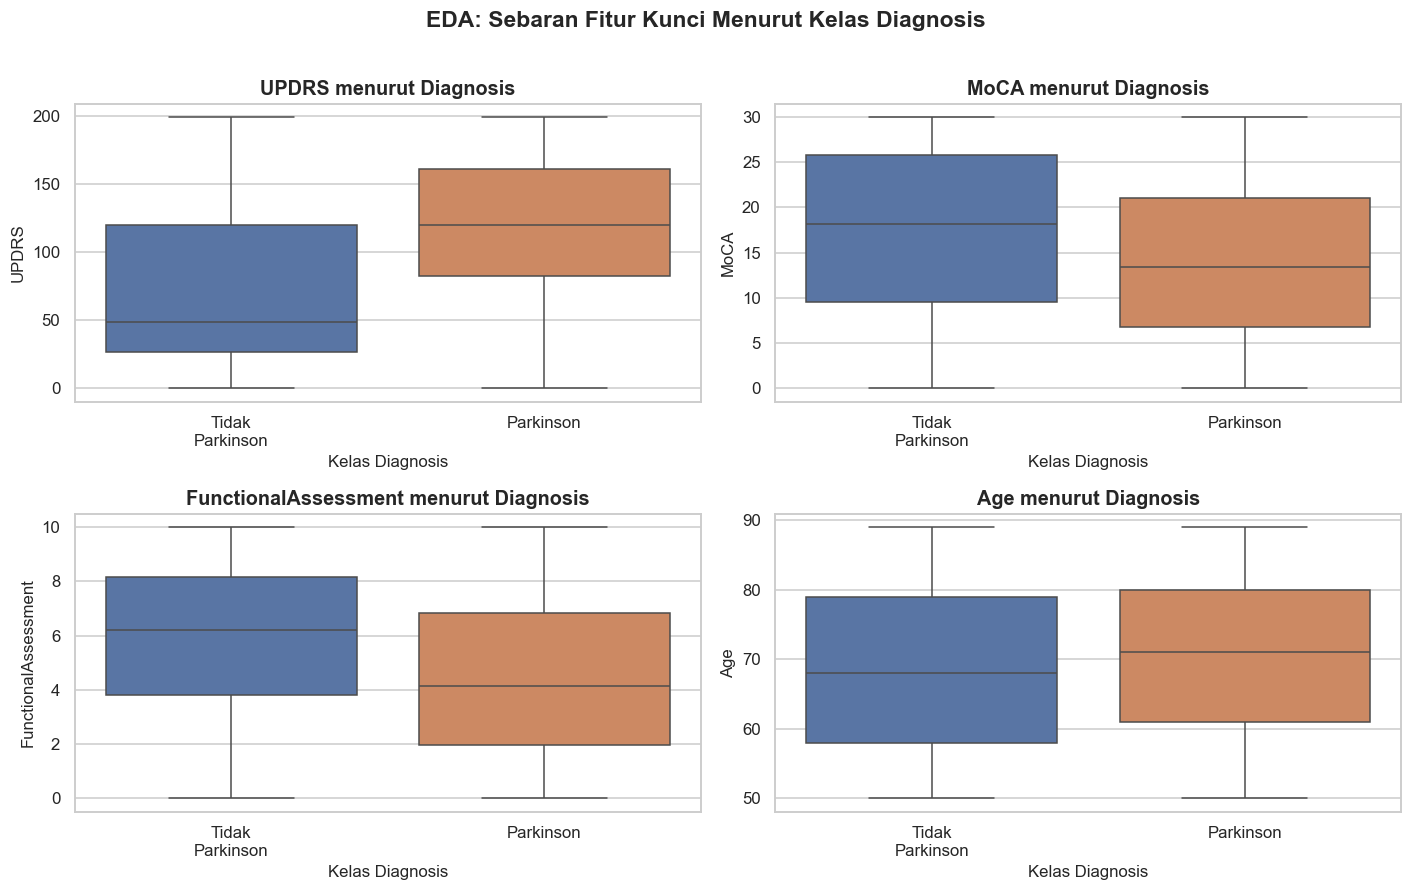

UPDRS           MoCA        FunctionalAssessment           Age           BMI       
                                mean  median   mean median                 mean median   mean median   mean median
Tidak Terdiagnosis Parkinson   72.68   48.58  17.00  18.19                 5.83   6.22  68.64   68.0  26.93  26.75
Terdiagnosis Parkinson        119.06  120.20  13.92  13.41                 4.47   4.15  70.20   71.0  27.38  27.48

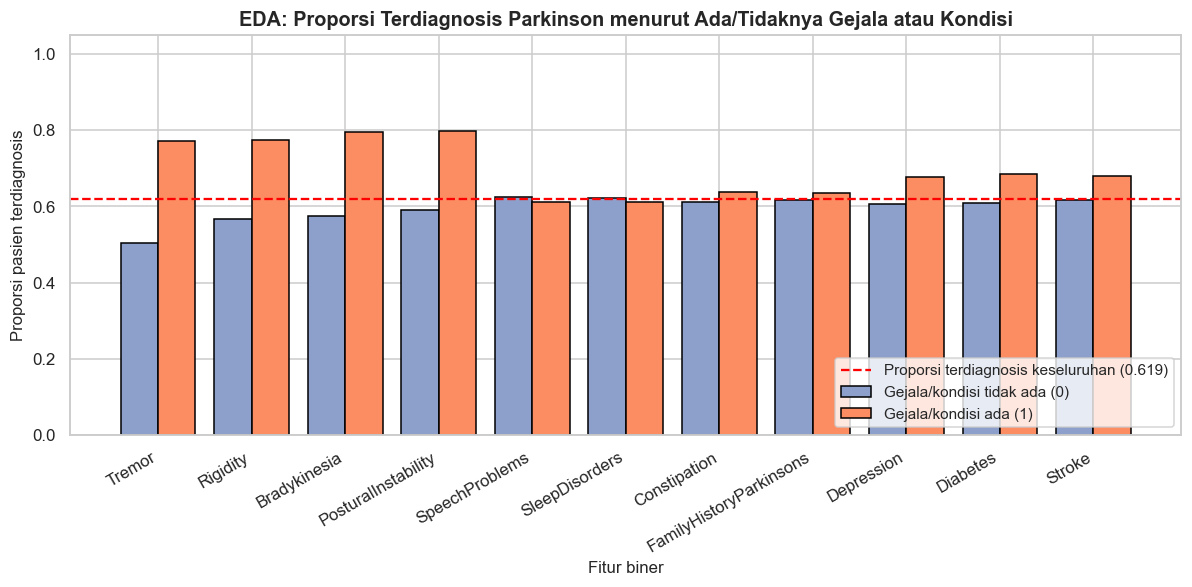

,proporsi terdiagnosis | tidak ada (0),proporsi terdiagnosis | ada (1),jumlah pasien 'ada',selisih
fitur,,,,
Tremor,0.503,0.772,909,0.269
Rigidity,0.567,0.774,532,0.207
Bradykinesia,0.574,0.794,437,0.220
PosturalInstability,0.591,0.798,292,0.207
SpeechProblems,0.623,0.610,621,-0.013
SleepDisorders,0.622,0.610,516,-0.012
Constipation,0.611,0.638,625,0.027
FamilyHistoryParkinsons,0.617,0.635,307,0.018
Depression,0.605,0.676,432,0.071


In [5]:
# Perbandingan fitur kunci antara pasien terdiagnosis dan tidak terdiagnosis Parkinson (boxplot)
key_features = ["UPDRS", "MoCA", "FunctionalAssessment", "Age"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), key_features):
    sns.boxplot(data=df, x=TARGET, y=col, order=CLASS_ORDER, hue=TARGET, hue_order=CLASS_ORDER,
                palette=CLASS_COLORS, legend=False, ax=ax, fliersize=2)
    ax.set_title(f"{col} menurut Diagnosis")
    ax.set_xlabel("Kelas Diagnosis")
    ax.set_ylabel(col)
    ax.set_xticks(range(len(CLASS_ORDER)))
    ax.set_xticklabels([SHORT_LABEL[c] for c in CLASS_ORDER])
plt.suptitle("EDA: Sebaran Fitur Kunci Menurut Kelas Diagnosis", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Rata-rata dan median fitur kunci per kelas
compare = df.groupby(TARGET)[["UPDRS", "MoCA", "FunctionalAssessment", "Age", "BMI"]].agg(["mean", "median"]).round(2)
compare.index = [CLASS_NAMES[i] for i in compare.index]
display(compare)

# Proporsi pasien terdiagnosis menurut ada/tidaknya gejala (hubungan fitur biner dengan Diagnosis)
symptom_cols = ["Tremor", "Rigidity", "Bradykinesia", "PosturalInstability", "SpeechProblems", "SleepDisorders", "Constipation"]
rate_rows = []
for c in symptom_cols + ["FamilyHistoryParkinsons", "Depression", "Diabetes", "Stroke"]:
    rate_rows.append({"fitur": c, "proporsi terdiagnosis | tidak ada (0)": df.loc[df[c] == 0, TARGET].mean(),
                      "proporsi terdiagnosis | ada (1)": df.loc[df[c] == 1, TARGET].mean(), "jumlah pasien 'ada'": int((df[c] == 1).sum())})
rate_df = pd.DataFrame(rate_rows).set_index("fitur")
rate_df["selisih"] = rate_df["proporsi terdiagnosis | ada (1)"] - rate_df["proporsi terdiagnosis | tidak ada (0)"]

fig, ax = plt.subplots(figsize=(11, 5.5))
xpos = np.arange(len(rate_df))
ax.bar(xpos - 0.2, rate_df["proporsi terdiagnosis | tidak ada (0)"], 0.4, color="#8da0cb", edgecolor="black", label="Gejala/kondisi tidak ada (0)")
ax.bar(xpos + 0.2, rate_df["proporsi terdiagnosis | ada (1)"], 0.4, color="#fc8d62", edgecolor="black", label="Gejala/kondisi ada (1)")
ax.axhline(df[TARGET].mean(), color="red", ls="--", lw=1.5, label=f"Proporsi terdiagnosis keseluruhan ({df[TARGET].mean():.3f})")
ax.set_xticks(xpos); ax.set_xticklabels(rate_df.index, rotation=30, ha="right")
ax.set_ylim(0, 1.05)
ax.set_title("EDA: Proporsi Terdiagnosis Parkinson menurut Ada/Tidaknya Gejala atau Kondisi")
ax.set_xlabel("Fitur biner")
ax.set_ylabel("Proporsi pasien terdiagnosis")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
display(rate_df.round(3))

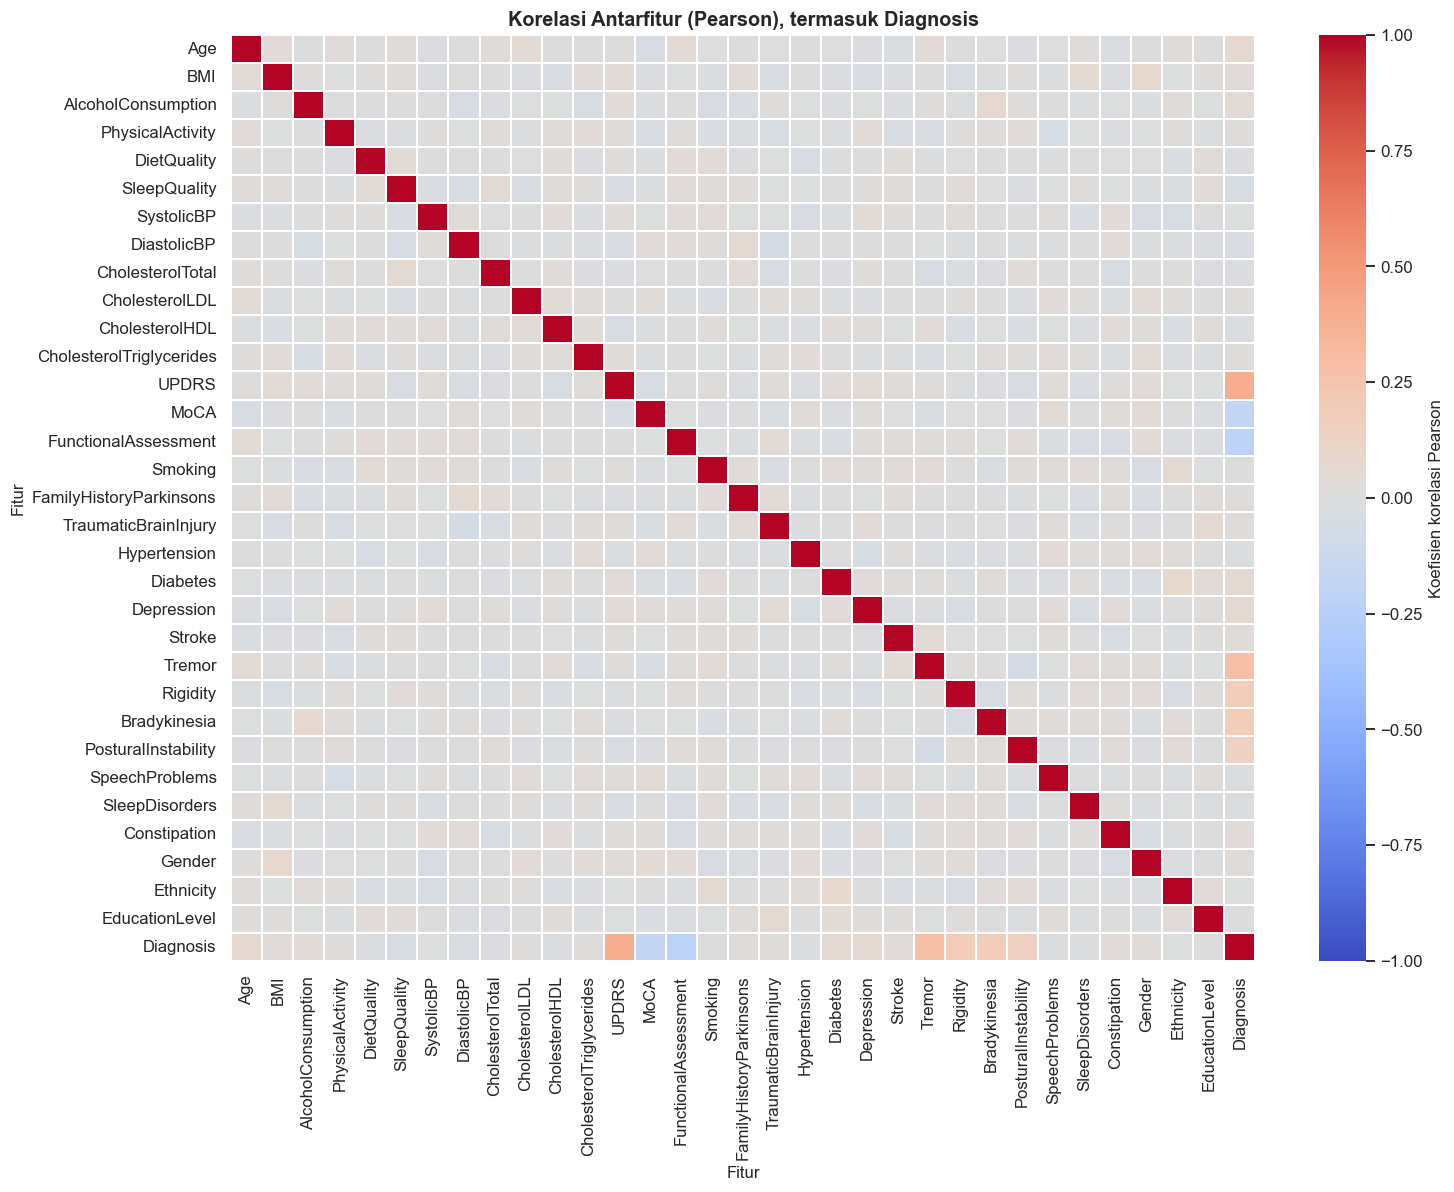

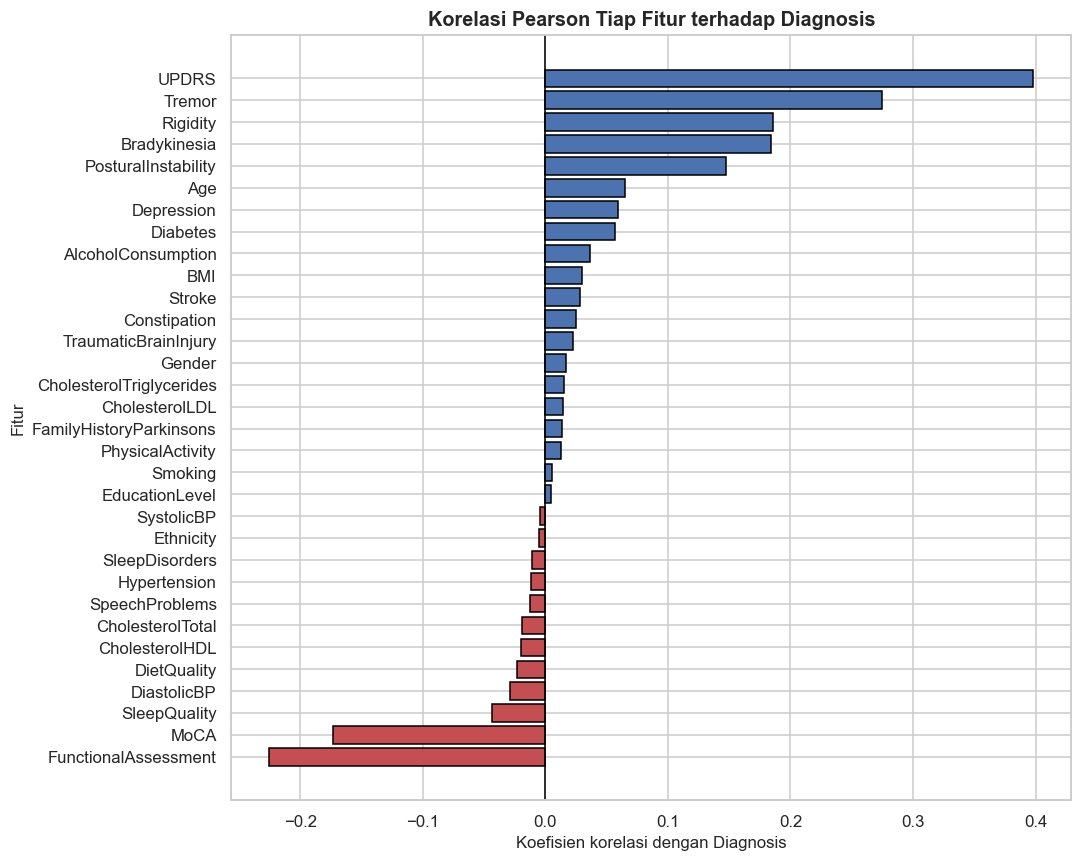

**Ringkasan korelasi:** korelasi absolut terbesar dengan `Diagnosis` dimiliki oleh `UPDRS` (+0.398), `Tremor` (+0.274), `FunctionalAssessment` (-0.225), `Rigidity` (+0.186), `Bradykinesia` (+0.184). Pasangan antarfitur terkuat hanya memiliki |r| = 0.076 (`Diabetes` & `Ethnicity`), sehingga tidak tampak multikolinearitas yang besar. Korelasi Pearson hanya menangkap hubungan **linear**; hubungan non-linear dan interaksi antarfitur (yang dapat dipelajari Random Forest) tidak terlihat di sini.

In [6]:
# Korelasi antarfitur numerik (Pearson) termasuk Diagnosis; kolom identitas tidak diikutkan
corr_cols = continuous_cols + binary_cols + nominal_cols + [TARGET]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.2,
            cbar_kws={"label": "Koefisien korelasi Pearson"}, ax=ax)
ax.set_title("Korelasi Antarfitur (Pearson), termasuk Diagnosis")
ax.set_xlabel("Fitur")
ax.set_ylabel("Fitur")
plt.tight_layout()
plt.show()

# Korelasi tiap fitur terhadap Diagnosis (urut menurut besarnya)
corr_target = corr[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
colors_c = ["#c44e52" if v < 0 else "#4c72b0" for v in corr_target.values]
ax.barh(corr_target.index, corr_target.values, color=colors_c, edgecolor="black")
ax.axvline(0, color="black", lw=1)
ax.set_title("Korelasi Pearson Tiap Fitur terhadap Diagnosis")
ax.set_xlabel("Koefisien korelasi dengan Diagnosis")
ax.set_ylabel("Fitur")
plt.tight_layout()
plt.show()

# Korelasi antarfitur (selain Diagnosis) yang paling kuat -> indikasi redundansi
feat_corr = corr.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones((len(corr) - 1,) * 2), k=1).astype(bool))
top_pairs = feat_corr.stack().abs().sort_values(ascending=False).head(5)
top_t = corr_target.abs().sort_values(ascending=False).head(5)
display(Markdown(
    "**Ringkasan korelasi:** korelasi absolut terbesar dengan `Diagnosis` dimiliki oleh "
    + ", ".join(f"`{n}` ({corr_target[n]:+.3f})" for n in top_t.index) + ". "
    + f"Pasangan antarfitur terkuat hanya memiliki |r| = {top_pairs.iloc[0]:.3f} (`{top_pairs.index[0][0]}` & `{top_pairs.index[0][1]}`), "
    + "sehingga tidak tampak multikolinearitas yang besar. Korelasi Pearson hanya menangkap hubungan **linear**; "
    + "hubungan non-linear dan interaksi antarfitur (yang dapat dipelajari Random Forest) tidak terlihat di sini."))

In [7]:
# Catatan karakteristik distribusi: seberapa dekat fitur kontinu dengan distribusi SERAGAM (uniform)?
# Statistik KS kecil = distribusi hampir seragam pada rentang [min, max]. Ini diagnostik deskriptif, bukan bukti pasti.
from scipy import stats
ks_rows = []
for c in [c for c in continuous_cols if df[c].nunique() > 100]:
    u = (df[c] - df[c].min()) / (df[c].max() - df[c].min())
    ks_rows.append({"fitur": c, "min": df[c].min(), "max": df[c].max(), "KS vs seragam": stats.kstest(u, "uniform").statistic})
ks_df = pd.DataFrame(ks_rows).sort_values("KS vs seragam").reset_index(drop=True)
display(ks_df.round(4))
n_uniform = int((ks_df["KS vs seragam"] < 0.05).sum())
display(Markdown(
    f"**Catatan:** **{n_uniform} dari {len(ks_df)}** fitur kontinu bernilai banyak memiliki statistik KS < 0,05 terhadap distribusi seragam, "
    "artinya sebarannya sangat rata dari nilai minimum ke maksimum. Pola ini **tidak lazim** pada pengukuran klinis nyata "
    "(yang umumnya menggumpal di sekitar nilai tengah dan memiliki ekor). Hal ini patut dicatat sebagai petunjuk bahwa dataset mungkin "
    "dibangkitkan secara simulasi/sintetis, sehingga hasil model sebaiknya tidak langsung digeneralisasi ke pasien nyata. "
    "Ini hanya petunjuk dari bentuk distribusi, bukan bukti bahwa data pasti sintetis."))

,fitur,min,max,KS vs seragam
0,SleepQuality,4.0005,9.9998,0.0142
1,PhysicalActivity,0.0042,9.9953,0.0144
2,FunctionalAssessment,0.0015,9.9927,0.0171
3,CholesterolTriglycerides,50.1136,399.9750,0.0171
4,CholesterolHDL,20.0280,99.9823,0.0174
5,CholesterolLDL,50.0228,199.9860,0.0181
6,MoCA,0.0212,29.9701,0.0183
7,AlcoholConsumption,0.0022,19.9889,0.0193
8,DietQuality,0.0000,9.9959,0.0203
9,CholesterolTotal,150.0627,299.9631,0.0247


**Catatan:** **12 dari 12** fitur kontinu bernilai banyak memiliki statistik KS < 0,05 terhadap distribusi seragam, artinya sebarannya sangat rata dari nilai minimum ke maksimum. Pola ini **tidak lazim** pada pengukuran klinis nyata (yang umumnya menggumpal di sekitar nilai tengah dan memiliki ekor). Hal ini patut dicatat sebagai petunjuk bahwa dataset mungkin dibangkitkan secara simulasi/sintetis, sehingga hasil model sebaiknya tidak langsung digeneralisasi ke pasien nyata. Ini hanya petunjuk dari bentuk distribusi, bukan bukti bahwa data pasti sintetis.

## 6. Pemeriksaan Missing Values dan Data Duplikat

- **Missing values** diperiksa per kolom. Jika ada, akan ditangani `SimpleImputer` (median untuk numerik, *most frequent* untuk kategorikal).
- **Data duplikat** diperiksa pada seluruh kolom, dan juga **setelah kolom identitas (`PatientID`) dibuang**. Baris yang identik pada seluruh fitur klinis tetapi memiliki `PatientID` berbeda tetap merupakan duplikat secara informasi, dan bila jatuh di train dan test sekaligus dapat membuat evaluasi terlalu optimis.

Jika dataset ternyata bersih, *pipeline* tetap memasukkan imputer agar **aman terhadap data baru yang memiliki nilai kosong**.

In [8]:
missing = df.isna().sum()
total_missing = int(missing.sum())
print(f"Total missing values : {total_missing}")
if total_missing > 0:
    display(missing[missing > 0].sort_values(ascending=False).rename("jumlah_missing").to_frame())
else:
    print("-> Tidak ada missing values pada dataset ini.")

n_dup = int(df.duplicated().sum())
print(f"\nJumlah baris duplikat (seluruh kolom)            : {n_dup}")
n_dup_noid = int(df.drop(columns=id_cols).duplicated().sum())
print(f"Jumlah baris duplikat (tanpa PatientID/Doctor)   : {n_dup_noid}")
if n_dup > 0 or n_dup_noid > 0:
    print("-> Terdapat duplikat; perlu dipertimbangkan sebelum split data.")
else:
    print("-> Tidak ada baris duplikat, sehingga tidak ada risiko baris yang sama muncul di train dan test.")
print(f"PatientID unik semua baris: {df['PatientID'].is_unique}")

Total missing values : 0
-> Tidak ada missing values pada dataset ini.

Jumlah baris duplikat (seluruh kolom)            : 0
Jumlah baris duplikat (tanpa PatientID/Doctor)   : 0
-> Tidak ada baris duplikat, sehingga tidak ada risiko baris yang sama muncul di train dan test.
PatientID unik semua baris: True


## 7. Analisis Distribusi Target

Distribusi kelas menentukan cara kita membaca hasil evaluasi. Bila satu kelas dominan, *accuracy* saja bisa menyesatkan: model yang selalu menebak kelas mayoritas pun tampak akurat. Karena itu evaluasi akhir akan menekankan **recall dan F1 per kelas**, *balanced accuracy*, dan *macro average*.

,jumlah,persentase (%)
0 = Tidak Terdiagnosis Parkinson,801,38.05
1 = Terdiagnosis Parkinson,1304,61.95


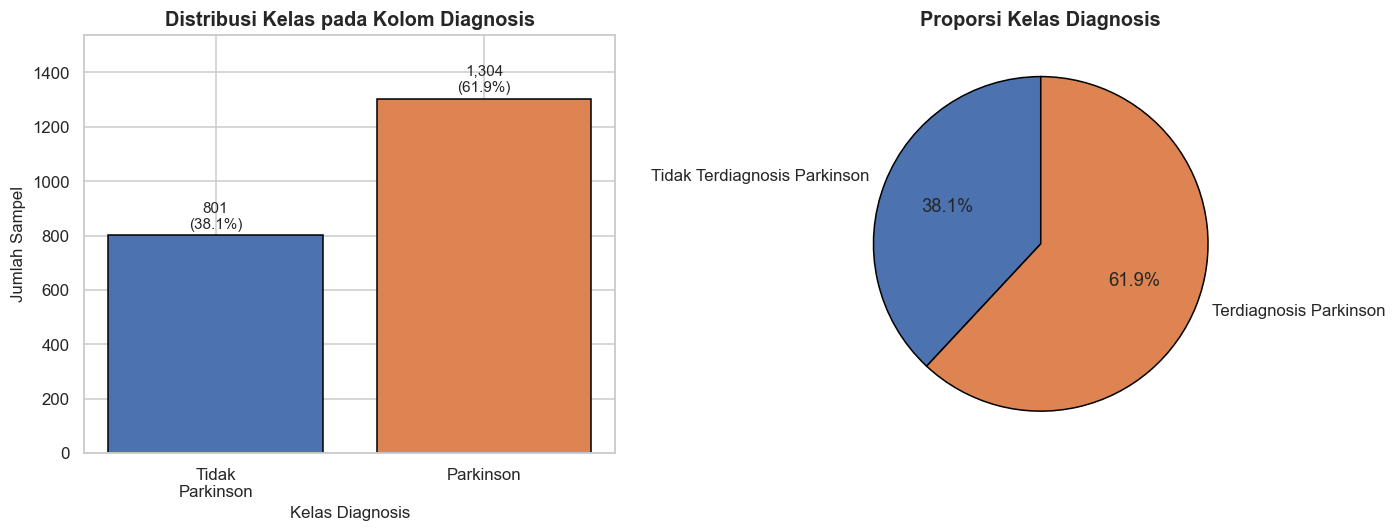

Kelas mayoritas : 1 = Terdiagnosis Parkinson (61.95%)
Kelas minoritas : 0 = Tidak Terdiagnosis Parkinson (38.05%)
Rasio mayoritas : minoritas = 1.63 : 1
-> Model 'tebak kelas mayoritas saja' sudah mencapai accuracy 61.95%. Ini baseline yang harus dilampaui, sekaligus alasan mengapa accuracy saja tidak cukup.


In [9]:
class_counts = df[TARGET].value_counts().reindex(CLASS_ORDER)
class_table = pd.DataFrame({"jumlah": class_counts, "persentase (%)": (class_counts / len(df) * 100).round(2)})
class_table.index = [f"{i} = {CLASS_NAMES[i]}" for i in class_table.index]
display(class_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
bars = ax.bar([SHORT_LABEL[c] for c in CLASS_ORDER], class_counts.values,
              color=[CLASS_COLORS[c] for c in CLASS_ORDER], edgecolor="black")
for b, v in zip(bars, class_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + class_counts.max() * 0.01,
            f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=10)
ax.set_title("Distribusi Kelas pada Kolom Diagnosis")
ax.set_xlabel("Kelas Diagnosis")
ax.set_ylabel("Jumlah Sampel")
ax.set_ylim(0, class_counts.max() * 1.18)

ax = axes[1]
ax.pie(class_counts.values, labels=[CLASS_NAMES[c] for c in CLASS_ORDER], autopct="%1.1f%%", startangle=90,
       colors=[CLASS_COLORS[c] for c in CLASS_ORDER], wedgeprops={"edgecolor": "black"})
ax.set_title("Proporsi Kelas Diagnosis")
plt.tight_layout()
plt.show()

majority = class_counts.idxmax()
minority = class_counts.idxmin()
baseline_acc = class_counts.max() / len(df)
ratio = class_counts.max() / class_counts.min()
print(f"Kelas mayoritas : {majority} = {CLASS_NAMES[majority]} ({baseline_acc:.2%})")
print(f"Kelas minoritas : {minority} = {CLASS_NAMES[minority]} ({class_counts.min() / len(df):.2%})")
print(f"Rasio mayoritas : minoritas = {ratio:.2f} : 1")
print(f"-> Model 'tebak kelas mayoritas saja' sudah mencapai accuracy {baseline_acc:.2%}. "
      f"Ini baseline yang harus dilampaui, sekaligus alasan mengapa accuracy saja tidak cukup.")

## 8. Preprocessing dan Encoding

### 8.1 Pemisahan fitur dan target
`Diagnosis` dipisahkan sebagai `y`. Dua kolom **tidak dipakai sebagai fitur** karena tidak membawa informasi klinis:

- **`PatientID`** — nomor pengenal pasien (unik pada setiap baris). Mengenali pasien lewat nomor bukan kemampuan klinis, dan nomor ini tidak akan bermakna pada pasien baru. Pemeriksaan di bawah juga memastikan nomor ini tidak berpola terhadap label.
- **`DoctorInCharge`** — kolom **konstan** (hanya satu nilai), sehingga tidak dapat membedakan kelas.

Selebihnya (**32 kolom**) menjadi kandidat fitur `X`.

### 8.2 Pemeriksaan risiko *target leakage*
*Target leakage* terjadi bila fitur membawa informasi yang secara langsung/definisional sama dengan label, atau baru diketahui **setelah** label ditentukan. Pada kasus Parkinson ini perlu kewaspadaan pada kelompok fitur **pemeriksaan klinis**:

- **`UPDRS`** (*Unified Parkinson's Disease Rating Scale*) adalah skala penilaian keparahan gejala motorik dan non-motorik yang dipakai pada pasien Parkinson. Nilai UPDRS tinggi lazimnya diperoleh setelah dokter menilai pasien dengan dugaan/diagnosis Parkinson, sehingga fitur ini dapat dekat dengan proses penegakan diagnosis itu sendiri.
- **`Tremor`, `Rigidity`, `Bradykinesia`, `PosturalInstability`** adalah gejala kardinal motorik yang menjadi dasar kriteria diagnosis Parkinson. `FunctionalAssessment` dan `MoCA` adalah penilaian fungsional/kognitif yang juga umumnya dilakukan pada evaluasi klinis.

**Penting:** kedekatan konseptual ini **belum membuktikan** adanya leakage. Maka fitur-fitur tersebut **tetap dipertahankan** pada model utama, dan keputusan diambil berdasarkan data: (a) apakah ada kolom yang bernama mencurigakan, (b) apakah `PatientID` berpola terhadap label, (c) seberapa tegas fitur klinis memisahkan kedua kelas (rentang nilai, tumpang tindih, dan ambang terbaik), dan (d) pada bagian 9.1 dan 14.1 seberapa besar model bergantung pada fitur-fitur itu. Keterbatasan: dataset tidak menyertakan **waktu pengukuran** relatif terhadap diagnosis, sehingga urutan kejadian (apakah UPDRS diukur sebelum atau sesudah diagnosis) tidak dapat diverifikasi dari data.

In [10]:
# Pisahkan fitur (X) dan label (y). Diagnosis TIDAK boleh ada di X.
X = df.drop(columns=[TARGET] + id_cols)
y = df[TARGET]
assert TARGET not in X.columns
print(f"X: {X.shape}  |  y: {y.shape}  |  jumlah fitur awal: {X.shape[1]}")
print("Kolom dibuang dari X (identitas/konstan):", id_cols)

# 1) Tidak ada kolom yang namanya mengindikasikan label/turunan label
suspicious = [c for c in X.columns if any(k in c.lower() for k in ["diagnos", "target", "label", "class", "status", "stage"])]
print("Kolom bernama mencurigakan di X:", suspicious if suspicious else "tidak ada")

# 2) PatientID: adakah pola terhadap label? (korelasi + perbandingan rentang per kelas)
id_corr = df["PatientID"].corr(df[TARGET])
print(f"\nKorelasi PatientID dengan Diagnosis: {id_corr:+.4f}")
display(df.groupby(TARGET)["PatientID"].agg(["min", "median", "max"]).rename(index=CLASS_NAMES))
print("-> PatientID " + ("tidak berpola terhadap label, namun tetap dibuang karena hanya pengenal."
                         if abs(id_corr) < 0.1 else "berpola terhadap label: dibuang agar model tidak memanfaatkan urutan data."))

# 3) Seberapa tegas fitur pemeriksaan klinis memisahkan kedua kelas? (min / median / max per kelas)
leak_cols = ["UPDRS", "MoCA", "FunctionalAssessment"]
leak_view = df.groupby(TARGET)[leak_cols].agg(["min", "median", "max"]).rename(index=CLASS_NAMES)
display(leak_view.round(2))

# 4) Tumpang tindih rentang nilai antar kelas + ambang tunggal terbaik (aturan 'nilai > ambang -> Parkinson')
print("Tumpang tindih rentang antar kelas dan akurasi ambang tunggal terbaik (seluruh data, tanpa model):")
for col in leak_cols:
    rng = df.groupby(TARGET)[col].agg(["min", "max"])
    ov_lo, ov_hi = max(rng["min"]), min(rng["max"])
    status = "TUMPANG TINDIH" if ov_lo < ov_hi else "terpisah tegas"
    thresholds = np.quantile(df[col], np.linspace(0.01, 0.99, 197))
    accs = [max(((df[col] > t) == df[TARGET]).mean(), ((df[col] <= t) == df[TARGET]).mean()) for t in thresholds]
    k = int(np.argmax(accs))
    print(f"  {col:<22}: rentang bersama {ov_lo:.2f}–{ov_hi:.2f} -> {status}; ambang terbaik {thresholds[k]:.2f} memberi akurasi {accs[k]:.3f}")
print("\nBandingkan dengan baseline tebak kelas mayoritas pada bagian 7: "
      f"{baseline_acc:.3f}. Bila sebuah ambang tunggal belum mendekati 1,0, label tidak ditentukan secara deterministik oleh fitur itu.")

X: (2105, 32)  |  y: (2105,)  |  jumlah fitur awal: 32
Kolom dibuang dari X (identitas/konstan): ['PatientID', 'DoctorInCharge']
Kolom bernama mencurigakan di X: tidak ada

Korelasi PatientID dengan Diagnosis: -0.0435


,min,median,max
Diagnosis,,,
Tidak Terdiagnosis Parkinson,3058,4166.0,5162
Terdiagnosis Parkinson,3059,4066.5,5161


-> PatientID tidak berpola terhadap label, namun tetap dibuang karena hanya pengenal.


UPDRS                  MoCA               FunctionalAssessment             
                               min  median     max   min median    max                  min median   max
Diagnosis                                                                                               
Tidak Terdiagnosis Parkinson  0.03   48.58  198.87  0.02  18.19  29.97                 0.01   6.22  9.99
Terdiagnosis Parkinson        0.20  120.20  198.95  0.04  13.41  29.96                 0.00   4.15  9.99

Tumpang tindih rentang antar kelas dan akurasi ambang tunggal terbaik (seluruh data, tanpa model):
  UPDRS                 : rentang bersama 0.20–198.87 -> TUMPANG TINDIH; ambang terbaik 49.54 memberi akurasi 0.773
  MoCA                  : rentang bersama 0.04–29.96 -> TUMPANG TINDIH; ambang terbaik 25.80 memberi akurasi 0.670
  FunctionalAssessment  : rentang bersama 0.01–9.99 -> TUMPANG TINDIH; ambang terbaik 7.37 memberi akurasi 0.633

Bandingkan dengan baseline tebak kelas mayoritas pada bagian 7: 0.619. Bila sebuah ambang tunggal belum mendekati 1,0, label tidak ditentukan secara deterministik oleh fitur itu.


### 8.3 Identifikasi tipe fitur dan pembangunan *Pipeline*

- Fitur dikelompokkan **berdasarkan makna**, bukan hanya tipe data: **numerik kontinu** (usia, BMI, tekanan darah, kolesterol, skor UPDRS/MoCA, dst.), serta **kategorikal** — yaitu kode nominal (`Gender`, `Ethnicity`, `EducationLevel`) dan penanda biner gejala/kondisi (`Tremor`, `Diabetes`, dst.). Kolom-kolom bertipe integer tersebut tidak boleh diperlakukan sebagai besaran numerik karena nilainya hanyalah kode.
- Numerik: `SimpleImputer(strategy="median")`. Kategorikal: `SimpleImputer(strategy="most_frequent")` lalu `OneHotEncoder(handle_unknown="ignore")`.
- Semuanya digabung dengan `ColumnTransformer` dan dibungkus bersama model dalam satu `Pipeline`. Dengan begitu imputer dan encoder **hanya di-*fit* pada data training** (saat `pipeline.fit(X_train, y_train)`), sehingga tidak ada kebocoran dari data testing.
- **Tidak ada `StandardScaler`**: Random Forest berbasis pohon keputusan sehingga tidak sensitif terhadap skala fitur.
- `handle_unknown="ignore"` membuat model aman jika data baru memuat kategori yang belum pernah terlihat.

In [11]:
# Identifikasi tipe fitur berdasarkan makna (telah divalidasi pada bagian 5)
categorical_features = nominal_cols + binary_cols
numeric_features = [c for c in X.columns if c not in categorical_features]
assert set(numeric_features) == set(continuous_cols)
assert len(numeric_features) + len(categorical_features) == X.shape[1]
print(f"Fitur numerik     ({len(numeric_features)}): {numeric_features}\n")
print(f"Fitur kategorikal ({len(categorical_features)}): {categorical_features}")


def make_preprocessor(num_cols, cat_cols):
    # Membuat ColumnTransformer: imputasi + one-hot encoding (tanpa scaling).
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([("num", numeric_pipe, num_cols),
                              ("cat", categorical_pipe, cat_cols)])


def build_pipeline(drop=(), **rf_params):
    # Pipeline lengkap: preprocessing + RandomForest.
    # 'drop' hanya dipakai untuk analisis sensitivitas diagnostik; model utama memakai semua 32 fitur.
    num = [c for c in numeric_features if c not in drop]
    cat = [c for c in categorical_features if c not in drop]
    rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **rf_params)
    return Pipeline([("preprocessor", make_preprocessor(num, cat)), ("model", rf)])


build_pipeline()   # tampilkan struktur pipeline

Fitur numerik     (15): ['Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'UPDRS', 'MoCA', 'FunctionalAssessment']

Fitur kategorikal (17): ['Gender', 'Ethnicity', 'EducationLevel', 'Smoking', 'FamilyHistoryParkinsons', 'TraumaticBrainInjury', 'Hypertension', 'Diabetes', 'Depression', 'Stroke', 'Tremor', 'Rigidity', 'Bradykinesia', 'PosturalInstability', 'SpeechProblems', 'SleepDisorders', 'Constipation']


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 9. Split Data 80:20

Data dibagi 80% training dan 20% testing dengan `random_state=42` dan **`stratify=y`**, sehingga proporsi setiap kelas di data training dan testing sama dengan proporsi aslinya. Hal ini penting agar kelas yang lebih kecil (di sini pasien tidak terdiagnosis) tetap terwakili pada data uji.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print(f"Data training : {X_train.shape[0]:,} baris  ({X_train.shape[0] / len(X):.0%})")
print(f"Data testing  : {X_test.shape[0]:,} baris  ({X_test.shape[0] / len(X):.0%})\n")

split_check = pd.DataFrame({
    "total (%)": (y.value_counts(normalize=True) * 100).reindex(CLASS_ORDER),
    "train (%)": (y_train.value_counts(normalize=True) * 100).reindex(CLASS_ORDER),
    "test (%)": (y_test.value_counts(normalize=True) * 100).reindex(CLASS_ORDER),
    "jumlah train": y_train.value_counts().reindex(CLASS_ORDER),
    "jumlah test": y_test.value_counts().reindex(CLASS_ORDER)}).round(2)
split_check.index = [f"{i} = {CLASS_NAMES[i]}" for i in split_check.index]
display(split_check)

Data training : 1,684 baris  (80%)
Data testing  : 421 baris  (20%)



,total (%),train (%),test (%),jumlah train,jumlah test
0 = Tidak Terdiagnosis Parkinson,38.05,38.06,38.0,641,160
1 = Terdiagnosis Parkinson,61.95,61.94,62.0,1043,261


### 9.1 Diagnostik separabilitas fitur tunggal (pemeriksaan *target leakage* berbasis data)

Untuk menguji kecurigaan pada bagian 8.2 secara empiris, setiap fitur dilatih **sendirian** (Random Forest kecil: 20 pohon, `max_depth=6`) pada data training lalu diuji pada data testing. Jika **satu fitur saja** sudah menghasilkan akurasi mendekati 100%, maka label hampir sepenuhnya ditentukan oleh fitur itu — entah karena label diturunkan dari fitur tersebut atau karena rentang nilai per kelas tidak tumpang tindih. Baseline pembanding adalah akurasi tebak kelas mayoritas.

Pada diagnostik ini **semua 32 fitur** diuji (numerik dan kategorikal), karena fitur gejala biner pun dapat membawa informasi diagnosis. Ini murni **diagnostik** (bukan pemilihan model dan bukan perbandingan algoritma).

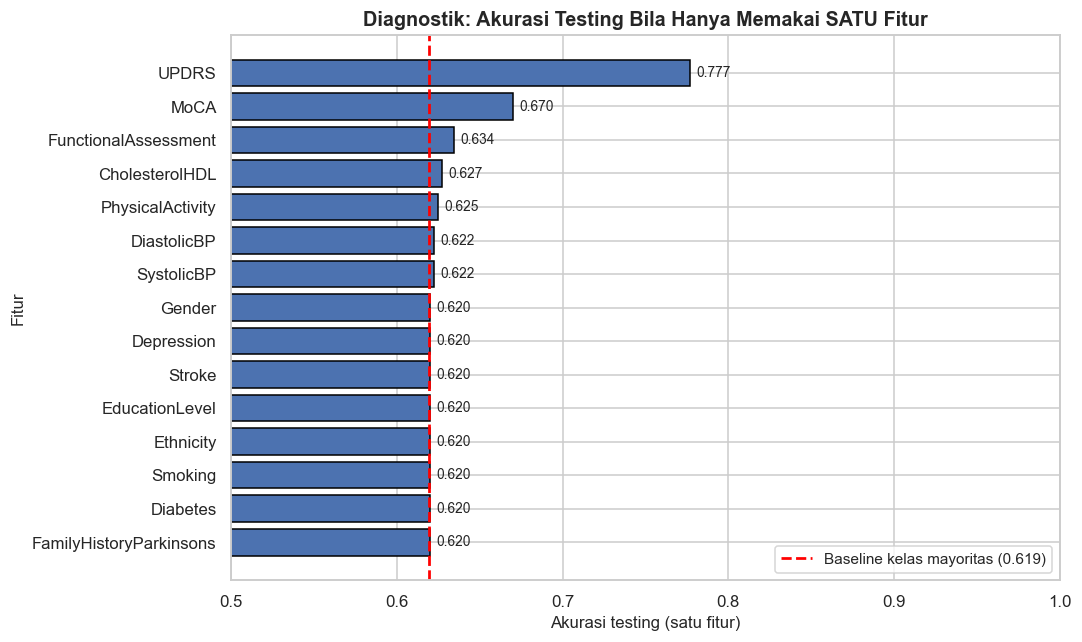

,fitur,akurasi_fitur_tunggal
0,UPDRS,0.7767
1,MoCA,0.6698
2,FunctionalAssessment,0.6342
3,CholesterolHDL,0.6271
4,PhysicalActivity,0.6247
5,DiastolicBP,0.6223
6,SystolicBP,0.6223
7,Gender,0.6200


**Temuan diagnostik:** **0** fitur mencapai akurasi >= 99,9% hanya dengan dirinya sendiri; **2** fitur melampaui baseline (0.619) dengan margin >= 0.05 (`UPDRS`, `MoCA`). Fitur tunggal terbaik (`UPDRS`) hanya mencapai 0.777, jauh di bawah 1,0. Jadi **tidak ada indikasi leakage deterministik** dari satu fitur: label tidak dapat direkonstruksi dari satu penanda saja. Namun fitur yang jelas melampaui baseline tetap membawa sinyal diagnosis yang kuat sehingga dampaknya diuji lagi pada analisis sensitivitas (14.1). Fitur lain yang hanya mendekati baseline berarti sendirian hampir tidak informatif.

In [13]:
single_rows = []
for col in X.columns:
    m = RandomForestClassifier(n_estimators=20, max_depth=6, random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train[[col]], y_train)
    single_rows.append({"fitur": col, "akurasi_fitur_tunggal": accuracy_score(y_test, m.predict(X_test[[col]]))})
single_feat = (pd.DataFrame(single_rows).sort_values("akurasi_fitur_tunggal", ascending=False).reset_index(drop=True))

top_single = single_feat.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_single["fitur"], top_single["akurasi_fitur_tunggal"], color="#4c72b0", edgecolor="black")
ax.axvline(baseline_acc, color="red", ls="--", lw=1.8, label=f"Baseline kelas mayoritas ({baseline_acc:.3f})")
for i, v in enumerate(top_single["akurasi_fitur_tunggal"]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.5, max(1.0, top_single["akurasi_fitur_tunggal"].max() + 0.08))
ax.set_title("Diagnostik: Akurasi Testing Bila Hanya Memakai SATU Fitur")
ax.set_xlabel("Akurasi testing (satu fitur)")
ax.set_ylabel("Fitur")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Ambang 'kuat': melampaui baseline paling tidak MARGIN_STRONG (ditetapkan dari data, bukan dari asumsi)
MARGIN_STRONG = 0.05
near_perfect = single_feat.loc[single_feat["akurasi_fitur_tunggal"] >= 0.999, "fitur"].tolist()
strong = single_feat.loc[single_feat["akurasi_fitur_tunggal"] >= baseline_acc + MARGIN_STRONG, "fitur"].tolist()
display(single_feat.head(8).round(4))
display(Markdown(
    f"**Temuan diagnostik:** **{len(near_perfect)}** fitur mencapai akurasi >= 99,9% hanya dengan dirinya sendiri; "
    f"**{len(strong)}** fitur melampaui baseline ({baseline_acc:.3f}) dengan margin >= {MARGIN_STRONG:.2f} "
    f"({', '.join('`'+f+'`' for f in strong) if strong else '-'}). "
    + ("Ini adalah **tanda kuat target leakage / keterpisahan sempurna**: label dapat direkonstruksi dari satu penanda tunggal."
       if near_perfect else
       f"Fitur tunggal terbaik (`{single_feat.iloc[0]['fitur']}`) hanya mencapai {single_feat.iloc[0]['akurasi_fitur_tunggal']:.3f}, jauh di bawah 1,0. "
       "Jadi **tidak ada indikasi leakage deterministik** dari satu fitur: label tidak dapat direkonstruksi dari satu penanda saja. "
       "Namun fitur yang jelas melampaui baseline tetap membawa sinyal diagnosis yang kuat sehingga dampaknya diuji lagi pada analisis sensitivitas (14.1). "
       "Fitur lain yang hanya mendekati baseline berarti sendirian hampir tidak informatif.")))

## 10. Skenario A — Pengaruh Jumlah Pohon (`n_estimators`)

Random Forest menggabungkan banyak pohon keputusan (*bagging* + pemilihan fitur acak). Secara teori, menambah jumlah pohon **menurunkan varians** prediksi sehingga hasil lebih stabil, tetapi keuntungannya makin kecil setelah jumlah tertentu (*diminishing returns*), sementara waktu pelatihan terus naik.

Eksperimen: `n_estimators = [10, 25, 50, 100, 200, 300, 500]`, parameter lain default (`max_depth=None`), `random_state=42`. Untuk tiap konfigurasi dicatat akurasi training/testing, selisihnya (*gap*), *balanced accuracy*, *macro F1*, **recall kelas terlemah**, *log loss*, waktu pelatihan, serta ukuran kompleksitas pohon (kedalaman dan jumlah daun) — agar kualitas pada kelas yang lebih kecil dan biaya komputasi ikut terpantau.

In [14]:
def fit_and_score(params, drop=()):
    # Latih satu pipeline dan kumpulkan metrik train/test + ukuran kompleksitas pohon.
    t0 = time.time()
    pipe = build_pipeline(drop=drop, **params)
    pipe.fit(X_train, y_train)                       # imputer/encoder di-fit HANYA pada data train
    pred_tr, pred_te = pipe.predict(X_train), pipe.predict(X_test)
    forest = pipe.named_steps["model"]
    return {
        "train_acc": accuracy_score(y_train, pred_tr),
        "test_acc": accuracy_score(y_test, pred_te),
        "gap": accuracy_score(y_train, pred_tr) - accuracy_score(y_test, pred_te),
        "test_bal_acc": balanced_accuracy_score(y_test, pred_te),
        "test_macro_f1": f1_score(y_test, pred_te, average="macro"),
        "min_class_recall": recall_score(y_test, pred_te, average=None, labels=CLASS_ORDER).min(),
        "test_log_loss": log_loss(y_test, pipe.predict_proba(X_test), labels=pipe.classes_),
        "max_tree_depth": int(max(t.get_depth() for t in forest.estimators_)),
        "avg_tree_depth": float(np.mean([t.get_depth() for t in forest.estimators_])),
        "avg_leaves": float(np.mean([t.get_n_leaves() for t in forest.estimators_])),
        "fit_sec": time.time() - t0,
        "recall_by_class": recall_score(y_test, pred_te, average=None, labels=CLASS_ORDER),
    }


n_estimators_list = [10, 25, 50, 100, 200, 300, 500]
rows_A = []
for n in n_estimators_list:
    res = fit_and_score({"n_estimators": n})
    rows_A.append({"n_estimators": n, **res})
    print(f"n_estimators={n:<4} | train={res['train_acc']:.4f} | test={res['test_acc']:.4f} | "
          f"waktu={res['fit_sec']:.1f}s")

results_A = pd.DataFrame(rows_A)
results_A["delta_test_acc"] = results_A["test_acc"].diff()
print("\nTabel hasil Skenario A:")
display(results_A.drop(columns="recall_by_class").round(4))

n_estimators=10   | train=0.9958 | test=0.9050 | waktu=0.3s
n_estimators=25   | train=0.9988 | test=0.9264 | waktu=0.2s
n_estimators=50   | train=1.0000 | test=0.9335 | waktu=0.3s
n_estimators=100  | train=1.0000 | test=0.9382 | waktu=0.4s
n_estimators=200  | train=1.0000 | test=0.9406 | waktu=0.6s
n_estimators=300  | train=1.0000 | test=0.9430 | waktu=0.8s
n_estimators=500  | train=1.0000 | test=0.9430 | waktu=1.3s

Tabel hasil Skenario A:


,n_estimators,train_acc,test_acc,gap,test_bal_acc,test_macro_f1,min_class_recall,test_log_loss,max_tree_depth,avg_tree_depth,avg_leaves,fit_sec,delta_test_acc
0,10,0.9958,0.9050,0.0909,0.8992,0.8992,0.8750,0.4739,19,17.1000,208.6000,0.2707,NaN
1,25,0.9988,0.9264,0.0724,0.9164,0.9210,0.8750,0.3064,22,17.4000,206.2800,0.2093,0.0214
2,50,1.0000,0.9335,0.0665,0.9258,0.9289,0.8938,0.3003,22,17.4200,205.4600,0.3099,0.0071
3,100,1.0000,0.9382,0.0618,0.9284,0.9336,0.8875,0.3023,22,17.5900,207.5000,0.4051,0.0048
4,200,1.0000,0.9406,0.0594,0.9328,0.9364,0.9000,0.3008,23,17.3650,207.7950,0.5952,0.0024
5,300,1.0000,0.9430,0.0570,0.9359,0.9391,0.9062,0.3036,25,17.3167,208.8067,0.8100,0.0024
6,500,1.0000,0.9430,0.0570,0.9359,0.9391,0.9062,0.3030,26,17.3000,208.8320,1.3201,0.0000


## 11. Visualisasi dan Analisis Skenario A

Panel kiri-atas menampilkan **akurasi training dan testing** terhadap jumlah pohon (sumbu x berskala logaritmik karena nilai `n_estimators` berjarak tidak merata). Panel kanan-atas melengkapinya dengan *balanced accuracy*, *macro F1*, dan recall kelas terlemah agar terlihat apakah perbaikan juga terjadi pada kelas yang lebih kecil. Baris bawah menampilkan **log loss** (kualitas probabilitas) serta **waktu pelatihan** dan **jumlah daun rata-rata** sebagai ukuran biaya dan kompleksitas.

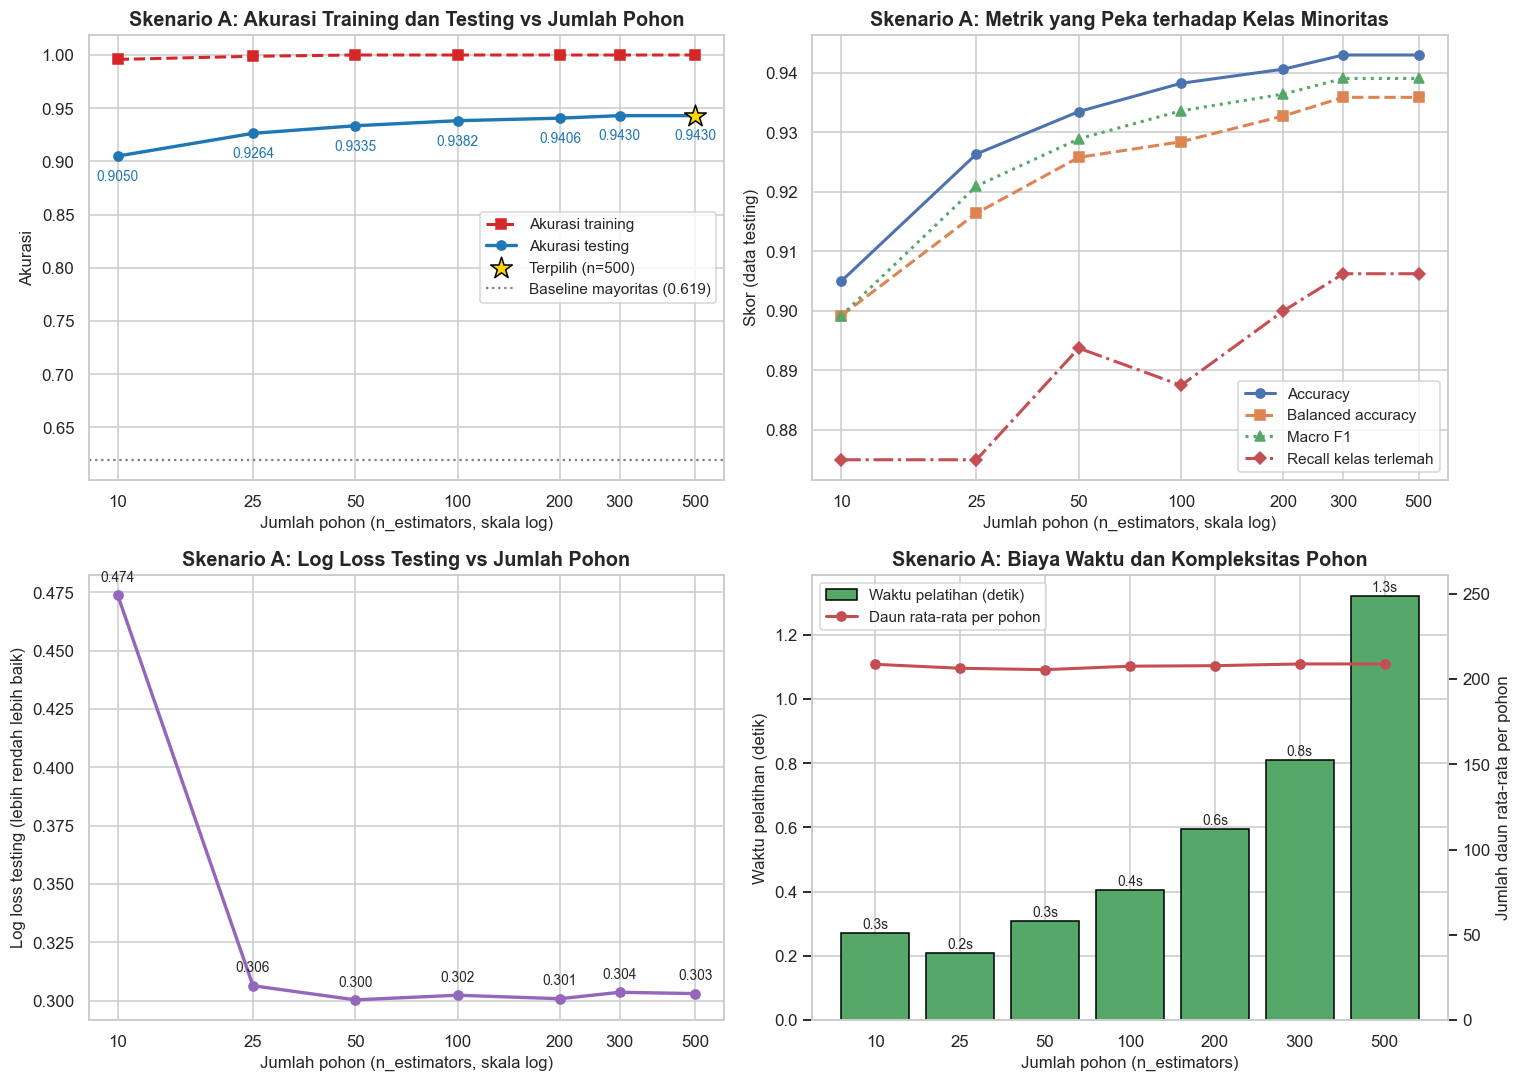

### Analisis otomatis Skenario A
- Dari **10** ke **500** pohon, akurasi testing berubah dari **0.9050** ke **0.9430** (+3.80 poin persentase); balanced accuracy dari 0.8992 ke 0.9359, macro F1 dari 0.8992 ke 0.9391.
- Peningkatan terbesar terjadi pada langkah menuju **25** pohon (+0.0214).
- Akurasi training berada pada kisaran 0.9958–1.0000 dan gap train–test 0.0570–0.0909.
- Log loss testing berubah dari 0.4739 (10 pohon) menjadi 0.3030 (500 pohon); nilai terendah 0.3003 pada n = 50.
- Waktu pelatihan naik sekitar **4.9x** (dari 0.3 ke 1.3 dtk), dan jumlah daun rata-rata per pohon berkisar 205.5–208.8.
- Akurasi testing relatif stabil (variasi <= 0.005) mulai ±100 pohon, tanda *diminishing returns*: pohon tambahan setelah itu hanya menambah waktu.
- **Konfigurasi terbaik:** akurasi testing tertinggi = 0.9430 (pertama dicapai pada n = 300). Dengan aturan 'konfigurasi dalam toleransi 0.001 -> pilih log loss testing terendah -> lalu paling sedikit pohon', terpilih **n_estimators = 500** (test acc 0.9430, balanced acc 0.9359, macro F1 0.9391, log loss 0.3030).

In [15]:
# Aturan pemilihan: akurasi testing tertinggi. Jika beberapa konfigurasi hanya berbeda <= TOL_A,
# bandingkan log loss testing (lebih rendah = probabilitas lebih yakin & tepat), lalu pilih yang paling sederhana.
TOL_A = 0.001
max_acc_A = results_A["test_acc"].max()
argmax_n = int(results_A.loc[results_A["test_acc"].idxmax(), "n_estimators"])
cand_A = results_A[results_A["test_acc"] >= max_acc_A - TOL_A].assign(ll=lambda d: d["test_log_loss"].round(4))
best_n = int(cand_A.sort_values(["ll", "n_estimators"]).iloc[0]["n_estimators"])
best_row = results_A[results_A["n_estimators"] == best_n].iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax = axes[0, 0]
ax.plot(results_A["n_estimators"], results_A["train_acc"], marker="s", lw=2, ls="--", color="#d62728", label="Akurasi training")
ax.plot(results_A["n_estimators"], results_A["test_acc"], marker="o", lw=2.2, color="#1f77b4", label="Akurasi testing")
for x_, y_ in zip(results_A["n_estimators"], results_A["test_acc"]):
    ax.annotate(f"{y_:.4f}", (x_, y_), textcoords="offset points", xytext=(0, -16), ha="center", fontsize=9, color="#1f77b4")
ax.scatter([best_n], [best_row["test_acc"]], s=220, marker="*", color="gold", edgecolor="black", zorder=5,
           label=f"Terpilih (n={best_n})")
ax.axhline(baseline_acc, color="gray", ls=":", lw=1.5, label=f"Baseline mayoritas ({baseline_acc:.3f})")
ax.set_xscale("log"); ax.set_xticks(n_estimators_list); ax.set_xticklabels(n_estimators_list)
ax.set_title("Skenario A: Akurasi Training dan Testing vs Jumlah Pohon")
ax.set_xlabel("Jumlah pohon (n_estimators, skala log)")
ax.set_ylabel("Akurasi")
ax.legend(loc="center right")

ax = axes[0, 1]
ax.plot(results_A["n_estimators"], results_A["test_acc"], marker="o", lw=2, label="Accuracy")
ax.plot(results_A["n_estimators"], results_A["test_bal_acc"], marker="s", lw=2, ls="--", label="Balanced accuracy")
ax.plot(results_A["n_estimators"], results_A["test_macro_f1"], marker="^", lw=2, ls=":", label="Macro F1")
ax.plot(results_A["n_estimators"], results_A["min_class_recall"], marker="D", lw=2, ls="-.", label="Recall kelas terlemah")
ax.set_xscale("log"); ax.set_xticks(n_estimators_list); ax.set_xticklabels(n_estimators_list)
ax.set_title("Skenario A: Metrik yang Peka terhadap Kelas Minoritas")
ax.set_xlabel("Jumlah pohon (n_estimators, skala log)")
ax.set_ylabel("Skor (data testing)")
ax.legend(loc="lower right")

ax = axes[1, 0]
ax.plot(results_A["n_estimators"], results_A["test_log_loss"], marker="o", lw=2.2, color="#9467bd")
for x_, y_ in zip(results_A["n_estimators"], results_A["test_log_loss"]):
    ax.annotate(f"{y_:.3f}", (x_, y_), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(n_estimators_list); ax.set_xticklabels(n_estimators_list)
ax.set_title("Skenario A: Log Loss Testing vs Jumlah Pohon")
ax.set_xlabel("Jumlah pohon (n_estimators, skala log)")
ax.set_ylabel("Log loss testing (lebih rendah lebih baik)")

ax = axes[1, 1]
ax.bar(range(len(results_A)), results_A["fit_sec"], color="#55a868", edgecolor="black", label="Waktu pelatihan (detik)")
for i, v in enumerate(results_A["fit_sec"]):
    ax.text(i, v + results_A["fit_sec"].max() * 0.01, f"{v:.1f}s", ha="center", fontsize=9)
ax.set_xticks(range(len(results_A))); ax.set_xticklabels(results_A["n_estimators"])
ax.set_xlabel("Jumlah pohon (n_estimators)")
ax.set_ylabel("Waktu pelatihan (detik)")
ax.set_title("Skenario A: Biaya Waktu dan Kompleksitas Pohon")
ax2 = ax.twinx()
ax2.plot(range(len(results_A)), results_A["avg_leaves"], color="#c44e52", marker="o", lw=2, label="Daun rata-rata per pohon")
ax2.set_ylabel("Jumlah daun rata-rata per pohon")
ax2.set_ylim(0, results_A["avg_leaves"].max() * 1.25)   # mulai dari nol agar variasi kecil tidak tampak berlebihan
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout()
plt.show()

# ----- Analisis otomatis (bercabang: akurasi berubah vs. akurasi identik/jenuh) -----
first, last = results_A.iloc[0], results_A.iloc[-1]
spread_A = results_A["test_acc"].max() - results_A["test_acc"].min()
time_ratio = last["fit_sec"] / first["fit_sec"]
text = ["### Analisis otomatis Skenario A"]
if spread_A < 1e-9:
    text += [f"- Akurasi testing **identik di semua variasi jumlah pohon** (**{first['test_acc']:.4f}**). Menambah pohon **tidak mengubah akurasi**.",
             f"- Yang berubah hanya **biaya**: waktu pelatihan naik sekitar **{time_ratio:.1f}x** (dari {first['fit_sec']:.1f} dtk ke {last['fit_sec']:.1f} dtk), "
             f"dan log loss testing bergerak dari {first['test_log_loss']:.4f} ke {last['test_log_loss']:.4f}."]
else:
    gain_total = last["test_acc"] - first["test_acc"]
    biggest = results_A.iloc[1:].loc[results_A.iloc[1:]["delta_test_acc"].idxmax()]
    plateau_n = next((int(results_A["n_estimators"].iloc[i]) for i in range(len(results_A))
                      if results_A["test_acc"].iloc[i:].max() - results_A["test_acc"].iloc[i:].min() <= TOL_A * 5), None)
    text += [f"- Dari **{int(first['n_estimators'])}** ke **{int(last['n_estimators'])}** pohon, akurasi testing berubah dari "
             f"**{first['test_acc']:.4f}** ke **{last['test_acc']:.4f}** ({gain_total*100:+.2f} poin persentase); "
             f"balanced accuracy dari {first['test_bal_acc']:.4f} ke {last['test_bal_acc']:.4f}, macro F1 dari {first['test_macro_f1']:.4f} ke {last['test_macro_f1']:.4f}.",
             f"- Peningkatan terbesar terjadi pada langkah menuju **{int(biggest['n_estimators'])}** pohon ({biggest['delta_test_acc']:+.4f}).",
             f"- Akurasi training berada pada kisaran {results_A['train_acc'].min():.4f}–{results_A['train_acc'].max():.4f} dan gap train–test {results_A['gap'].min():.4f}–{results_A['gap'].max():.4f}.",
             f"- Log loss testing berubah dari {first['test_log_loss']:.4f} (10 pohon) menjadi {last['test_log_loss']:.4f} (500 pohon); nilai terendah {results_A['test_log_loss'].min():.4f} "
             f"pada n = {int(results_A.loc[results_A['test_log_loss'].idxmin(), 'n_estimators'])}.",
             f"- Waktu pelatihan naik sekitar **{time_ratio:.1f}x** (dari {first['fit_sec']:.1f} ke {last['fit_sec']:.1f} dtk), dan jumlah daun rata-rata per pohon "
             f"berkisar {results_A['avg_leaves'].min():.1f}–{results_A['avg_leaves'].max():.1f}."]
    if plateau_n is not None:
        text.append(f"- Akurasi testing relatif stabil (variasi <= {TOL_A * 5:.3f}) mulai ±{plateau_n} pohon, tanda *diminishing returns*: pohon tambahan setelah itu hanya menambah waktu.")
    else:
        text.append("- Akurasi testing belum benar-benar mendatar pada rentang yang diuji; masih ada fluktuasi antar konfigurasi.")
text.append(f"- **Konfigurasi terbaik:** akurasi testing tertinggi = {max_acc_A:.4f} (pertama dicapai pada n = {argmax_n}). "
            f"Dengan aturan 'konfigurasi dalam toleransi {TOL_A:.3f} -> pilih log loss testing terendah -> lalu paling sedikit pohon', "
            f"terpilih **n_estimators = {best_n}** (test acc {best_row['test_acc']:.4f}, balanced acc {best_row['test_bal_acc']:.4f}, "
            f"macro F1 {best_row['test_macro_f1']:.4f}, log loss {best_row['test_log_loss']:.4f}).")
display(Markdown("\n".join(text)))

## 12. Skenario B — Pengaruh Kedalaman Pohon (`max_depth`)

`max_depth` membatasi seberapa dalam pohon boleh tumbuh, sehingga mengontrol **kompleksitas model**:

- **Terlalu dangkal** → pohon tidak cukup mampu menangkap pola → *underfitting* (akurasi rendah di training **dan** testing).
- **Sangat dalam / tanpa batas (`None`)** → pohon bisa menghafal data training → akurasi training sangat tinggi dan selisih train–test dapat melebar.

> ⚠️ Akurasi training tinggi **belum otomatis berarti overfitting**. Pada Random Forest, pohon tanpa batas hampir selalu mencapai akurasi training ≈ 100% karena data training masuk ke dalam *bootstrap* masing-masing pohon. Yang menentukan adalah apakah **performa testing ikut membaik atau memburuk** dan bagaimana hasil per kelas.

Eksperimen memakai `n_estimators` terbaik dari Skenario A, dengan `max_depth = [3, 5, 10, 20, None]`.

In [16]:
depth_options = {"3": 3, "5": 5, "10": 10, "20": 20, "None": None}   # label -> nilai parameter
rows_B = []
for label, depth in depth_options.items():
    res = fit_and_score({"n_estimators": best_n, "max_depth": depth})
    rows_B.append({"max_depth": label, **res})
    print(f"max_depth={label:<5} | train={res['train_acc']:.4f} | test={res['test_acc']:.4f} | "
          f"gap={res['gap']:.4f} | rata2 kedalaman pohon={res['avg_tree_depth']:.1f}")

results_B = pd.DataFrame(rows_B)
print(f"\nTabel hasil Skenario B (n_estimators = {best_n}):")
display(results_B.drop(columns="recall_by_class").round(4))

max_depth=3     | train=0.7993 | test=0.7957 | gap=0.0036 | rata2 kedalaman pohon=3.0
max_depth=5     | train=0.9442 | test=0.9454 | gap=-0.0012 | rata2 kedalaman pohon=5.0
max_depth=10    | train=0.9887 | test=0.9406 | gap=0.0481 | rata2 kedalaman pohon=10.0
max_depth=20    | train=1.0000 | test=0.9430 | gap=0.0570 | rata2 kedalaman pohon=17.2
max_depth=None  | train=1.0000 | test=0.9430 | gap=0.0570 | rata2 kedalaman pohon=17.3

Tabel hasil Skenario B (n_estimators = 500):


,max_depth,train_acc,test_acc,gap,test_bal_acc,test_macro_f1,min_class_recall,test_log_loss,max_tree_depth,avg_tree_depth,avg_leaves,fit_sec
0,3,0.7993,0.7957,0.0036,0.7325,0.7468,0.4688,0.4936,3,3.000,7.920,1.4689
1,5,0.9442,0.9454,-0.0012,0.9318,0.9407,0.8750,0.4182,5,5.000,27.368,1.2255
2,10,0.9887,0.9406,0.0481,0.9303,0.9361,0.8875,0.3213,10,10.000,142.918,2.2946
3,20,1.0000,0.9430,0.0570,0.9359,0.9391,0.9062,0.3034,20,17.174,208.648,1.8601
4,None,1.0000,0.9430,0.0570,0.9359,0.9391,0.9062,0.3030,26,17.300,208.832,1.3614


## 13. Visualisasi dan Analisis Skenario B

Grafik kiri membandingkan **akurasi training vs testing** untuk tiap kedalaman (urut dari paling dangkal ke tanpa batas); area di antara dua garis adalah *gap*. Grafik kanan menunjukkan **kedalaman aktual rata-rata dan maksimum pohon** sebagai ukuran kompleksitas model. Di bawahnya, *heatmap* recall per kelas memastikan tidak ada kelas yang tersembunyi di balik *accuracy*.

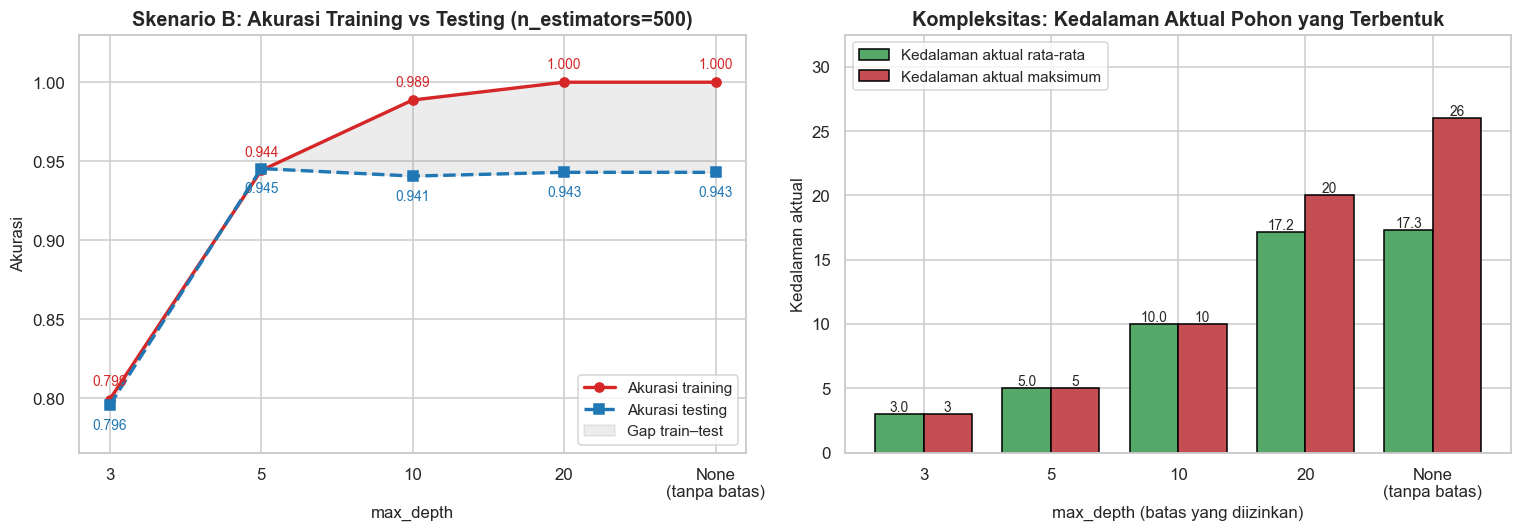

Recall per kelas (data testing) untuk tiap max_depth:


,Tidak Parkinson,Parkinson
max_depth,,
3,0.469,0.996
5,0.875,0.989
10,0.888,0.973
20,0.906,0.966
None,0.906,0.966


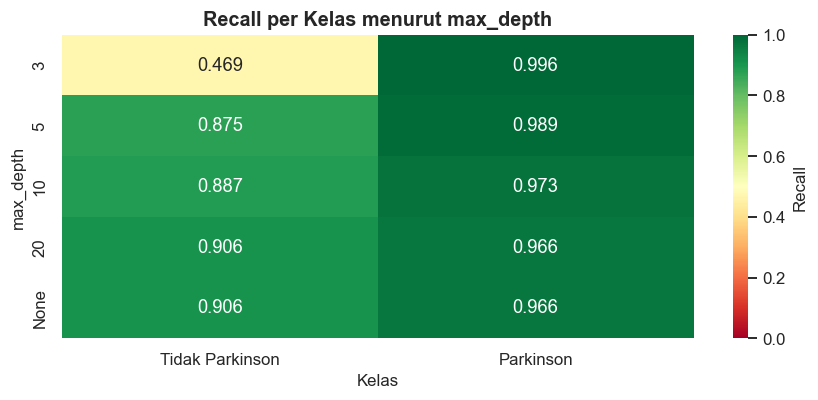

,max_depth,train_acc,test_acc,gap,min_class_recall,test_log_loss,max_tree_depth,diagnosis
0,3,0.7993,0.7957,0.0036,0.4688,0.4936,3,"Indikasi UNDERFITTING: gap kecil, tetapi kelas 'Tidak Parkinson' hampir tidak dikenali (recall 0.47); accuracy tingg..."
1,5,0.9442,0.9454,-0.0012,0.8750,0.4182,5,"Seimbang (gap kecil, semua kelas dikenali dengan baik)"
2,10,0.9887,0.9406,0.0481,0.8875,0.3213,10,"Seimbang (gap kecil, semua kelas dikenali dengan baik)"
3,20,1.0000,0.9430,0.0570,0.9062,0.3034,20,"Gap besar, tetapi test kompetitif -> bukan overfitting yang merugikan"
4,None,1.0000,0.9430,0.0570,0.9062,0.3030,26,"Gap besar, tetapi test kompetitif -> bukan overfitting yang merugikan"


### Analisis otomatis Skenario B
- **Kompleksitas:** tanpa batas (`None`), pohon tumbuh sampai kedalaman maksimum **26** (rata-rata 17.3, rata-rata 208.8 daun). Dengan `max_depth=3` kedalaman rata-rata 3.0 dan jumlah daun rata-rata 7.9. Jumlah daun rata-rata untuk 3/5/10/20/None: 8 / 27 / 143 / 209 / 209.
- Semua batas kedalaman (3, 5, 10, 20) **mengikat**: setidaknya sebagian pohon terhenti oleh batas tersebut (pada batas 20 kedalaman rata-rata 17.2, jadi sebagian besar pohon sudah berhenti sendiri sebelum 20), sedangkan tanpa batas pohon dapat tumbuh hingga kedalaman 26.
- **Dari yang paling dangkal ke tanpa batas:** akurasi testing 0.7957 → 0.9454 → 0.9406 → 0.9430 → 0.9430; akurasi training 0.7993 → 0.9442 → 0.9887 → 1.0000 → 1.0000.
- **Underfitting** terindikasi pada `max_depth` = 3. Pada `max_depth=3`: train 0.7993 dan test 0.7957 (sama-sama rendah, gap hanya 0.0036), balanced accuracy 0.7325, macro F1 0.7468, recall kelas terlemah (Tidak Parkinson) = 0.469. Pohon dangkal tidak punya kapasitas menangkap pola interaksi antar-fitur.
- **Gap besar tetapi bukan overfitting yang merugikan:** pada `max_depth` = 20, None gap train–test > 0,05 (maks 0.0570) karena akurasi training mencapai ~100% (efek *bootstrap* pada Random Forest). Akurasi testingnya (0.9430, 0.9430) hanya berbeda 0.0024 dari yang tertinggi (0.9454); memperdalam pohon melampaui titik tersebut tidak meningkatkan akurasi testing, hanya menambah kompleksitas.
- **Konfigurasi terbaik:** `max_depth = 5` (test acc 0.9454, gap -0.0012, recall kelas terlemah 0.8750, log loss 0.4182). Aturan: akurasi dalam 0.002 dari yang tertinggi dan semua kelas dikenali, lalu gap terkecil, log loss terendah, dan paling sederhana.

In [17]:
# Urutan tampilan dari paling sederhana ke paling kompleks
plot_order = ["3", "5", "10", "20", "None"]
rb = results_B.set_index("max_depth").loc[plot_order].reset_index()
xlabels = [l if l != "None" else "None\n(tanpa batas)" for l in rb["max_depth"]]
xpos = np.arange(len(rb))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(xpos, rb["train_acc"], marker="o", lw=2.2, color="#d62728", label="Akurasi training")
ax.plot(xpos, rb["test_acc"], marker="s", lw=2.2, ls="--", color="#1f77b4", label="Akurasi testing")
ax.fill_between(xpos, rb["test_acc"], rb["train_acc"], color="gray", alpha=0.15, label="Gap train–test")
for i, rr in rb.iterrows():
    ax.annotate(f"{rr['train_acc']:.3f}", (i, rr["train_acc"]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, color="#d62728")
    ax.annotate(f"{rr['test_acc']:.3f}", (i, rr["test_acc"]), textcoords="offset points", xytext=(0, -16), ha="center", fontsize=9, color="#1f77b4")
ax.set_xticks(xpos); ax.set_xticklabels(xlabels)
ax.set_title(f"Skenario B: Akurasi Training vs Testing (n_estimators={best_n})")
ax.set_xlabel("max_depth")
ax.set_ylabel("Akurasi")
ax.set_ylim(min(rb["test_acc"].min(), rb["train_acc"].min()) - 0.03, 1.03)
ax.legend(loc="lower right")

ax = axes[1]
w = 0.38
ax.bar(xpos - w / 2, rb["avg_tree_depth"], w, color="#55a868", edgecolor="black", label="Kedalaman aktual rata-rata")
ax.bar(xpos + w / 2, rb["max_tree_depth"], w, color="#c44e52", edgecolor="black", label="Kedalaman aktual maksimum")
for i, (a_, m_) in enumerate(zip(rb["avg_tree_depth"], rb["max_tree_depth"])):
    ax.text(i - w / 2, a_ + 0.2, f"{a_:.1f}", ha="center", fontsize=9)
    ax.text(i + w / 2, m_ + 0.2, f"{m_}", ha="center", fontsize=9)
ax.set_xticks(xpos); ax.set_xticklabels(xlabels)
ax.set_title("Kompleksitas: Kedalaman Aktual Pohon yang Terbentuk")
ax.set_xlabel("max_depth (batas yang diizinkan)")
ax.set_ylabel("Kedalaman aktual")
ax.set_ylim(0, rb["max_tree_depth"].max() * 1.25)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# ----- Recall per kelas untuk tiap kedalaman (agar kelas yang lebih kecil tidak tersembunyi di balik accuracy) -----
recall_B = pd.DataFrame(np.vstack(results_B["recall_by_class"].values), index=results_B["max_depth"],
                        columns=[flat(SHORT_LABEL[c]) for c in CLASS_ORDER]).loc[plot_order]
recall_B.index.name = "max_depth"
print("Recall per kelas (data testing) untuk tiap max_depth:")
display(recall_B.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(recall_B, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "Recall"}, ax=ax)
ax.set_title("Recall per Kelas menurut max_depth")
ax.set_xlabel("Kelas")
ax.set_ylabel("max_depth")
plt.tight_layout()
plt.show()

# ----- Diagnosis fit per konfigurasi -----
best_test_B = results_B["test_acc"].max()
def diagnose(rw):
    rec = np.asarray(rw["recall_by_class"])
    worst_cls = flat(SHORT_LABEL[CLASS_ORDER[int(rec.argmin())]])
    if rec.min() < 0.5 and rw["gap"] < 0.02:
        return (f"Indikasi UNDERFITTING: gap kecil, tetapi kelas '{worst_cls}' hampir tidak dikenali "
                f"(recall {rec.min():.2f}); accuracy tinggi dapat menyembunyikannya")
    if rw["test_acc"] < best_test_B - 0.01:
        return "Indikasi UNDERFITTING: performa train dan test sama-sama di bawah yang terbaik"
    if rw["gap"] > 0.05 and rw["test_acc"] < best_test_B - 0.005:
        return "Indikasi OVERFITTING: gap besar DAN test lebih rendah dari konfigurasi terbaik"
    if rw["gap"] > 0.05:
        return "Gap besar, tetapi test kompetitif -> bukan overfitting yang merugikan"
    return "Seimbang (gap kecil, semua kelas dikenali dengan baik)"
results_B["diagnosis"] = results_B.apply(diagnose, axis=1)
pd.set_option("display.max_colwidth", 120)
display(results_B[["max_depth", "train_acc", "test_acc", "gap", "min_class_recall", "test_log_loss", "max_tree_depth", "diagnosis"]].round(4))

# ----- Pemilihan max_depth terbaik -----
# Kandidat: test acc dalam TOL_B dari yang tertinggi DAN semua kelas dikenali (min recall >= 0.5).
# Dari kandidat pilih gap terkecil (stabil), lalu log loss terendah, lalu yang lebih dangkal (lebih sederhana).
TOL_B = 0.002
order_map = {"3": 0, "5": 1, "10": 2, "20": 3, "None": 4}
cand_B = results_B[(results_B["test_acc"] >= best_test_B - TOL_B) & (results_B["min_class_recall"] >= 0.5)].copy()
cand_B["order"] = cand_B["max_depth"].map(order_map)
cand_B["gap_r"], cand_B["ll_r"] = cand_B["gap"].round(4), cand_B["test_log_loss"].round(4)
chosen = cand_B.sort_values(["gap_r", "ll_r", "order"]).iloc[0]
best_depth_label = chosen["max_depth"]
best_depth = depth_options[best_depth_label]

# Batas kedalaman yang 'mengikat' = benar-benar menghentikan pertumbuhan pohon
rb_idx = results_B.set_index("max_depth")
def binding(lbl):
    lim = depth_options[lbl]
    return lim is not None and rb_idx.loc[lbl, "max_tree_depth"] >= lim
free_depth = int(rb_idx.loc["None", "max_tree_depth"])
not_binding = [l for l in ["3", "5", "10", "20"] if not binding(l)]
shallow = rb_idx.loc["3"]; deep = rb_idx.loc["None"]
under_labels = [l for l, d in zip(results_B["max_depth"], results_B["diagnosis"]) if d.startswith("Indikasi UNDERFITTING")]
over_labels = [l for l, d in zip(results_B["max_depth"], results_B["diagnosis"]) if d.startswith("Indikasi OVERFITTING")]
comp_labels = [l for l, d in zip(results_B["max_depth"], results_B["diagnosis"]) if d.startswith("Gap besar")]
worst_cls3 = flat(SHORT_LABEL[CLASS_ORDER[int(np.asarray(shallow["recall_by_class"]).argmin())]])

text = ["### Analisis otomatis Skenario B",
        f"- **Kompleksitas:** tanpa batas (`None`), pohon tumbuh sampai kedalaman maksimum **{free_depth}** (rata-rata {deep['avg_tree_depth']:.1f}, "
        f"rata-rata {deep['avg_leaves']:.1f} daun). Dengan `max_depth=3` kedalaman rata-rata {shallow['avg_tree_depth']:.1f} dan jumlah daun rata-rata "
        f"{shallow['avg_leaves']:.1f}. Jumlah daun rata-rata untuk 3/5/10/20/None: "
        + " / ".join(f"{rb_idx.loc[l, 'avg_leaves']:.0f}" for l in plot_order) + ".",
        (f"- Batas `max_depth` = {', '.join(not_binding)} **tidak pernah tercapai** (pohon berhenti sebelum batas), sehingga model tersebut praktis "
         f"identik dengan `None`." if not_binding else "- Semua batas kedalaman (3, 5, 10, 20) **mengikat**: setidaknya sebagian pohon terhenti oleh batas tersebut "
         f"(pada batas 20 kedalaman rata-rata {rb_idx.loc['20', 'avg_tree_depth']:.1f}, jadi sebagian besar pohon sudah berhenti sendiri sebelum 20), "
         f"sedangkan tanpa batas pohon dapat tumbuh hingga kedalaman {free_depth}."),
        f"- **Dari yang paling dangkal ke tanpa batas:** akurasi testing " + " → ".join(f"{rb_idx.loc[l, 'test_acc']:.4f}" for l in plot_order)
        + "; akurasi training " + " → ".join(f"{rb_idx.loc[l, 'train_acc']:.4f}" for l in plot_order) + "."]
if under_labels:
    text.append(f"- **Underfitting** terindikasi pada `max_depth` = {', '.join(under_labels)}. Pada `max_depth=3`: train {shallow['train_acc']:.4f} dan test {shallow['test_acc']:.4f} "
                f"(sama-sama rendah, gap hanya {shallow['gap']:.4f}), balanced accuracy {shallow['test_bal_acc']:.4f}, macro F1 {shallow['test_macro_f1']:.4f}, "
                f"recall kelas terlemah ({worst_cls3}) = {np.asarray(shallow['recall_by_class']).min():.3f}. Pohon dangkal tidak punya kapasitas menangkap pola interaksi antar-fitur.")
else:
    text.append(f"- Tidak ada konfigurasi yang terindikasi underfitting menurut aturan diagnosis (accuracy `max_depth=3` = {shallow['test_acc']:.4f}).")
if over_labels:
    text.append(f"- **Overfitting yang merugikan** terindikasi pada `max_depth` = {', '.join(over_labels)} (gap besar dan akurasi testing di bawah yang terbaik).")
elif comp_labels:
    comp_accs = [rb_idx.loc[l, "test_acc"] for l in comp_labels]
    text.append(f"- **Gap besar tetapi bukan overfitting yang merugikan:** pada `max_depth` = {', '.join(comp_labels)} gap train–test > 0,05 "
                f"(maks {results_B['gap'].max():.4f}) karena akurasi training mencapai ~100% (efek *bootstrap* pada Random Forest). Akurasi testingnya "
                f"({', '.join(f'{v_:.4f}' for v_ in comp_accs)}) hanya berbeda {best_test_B - min(comp_accs):.4f} dari yang tertinggi ({best_test_B:.4f}); "
                f"memperdalam pohon melampaui titik tersebut tidak meningkatkan akurasi testing, hanya menambah kompleksitas.")
else:
    text.append(f"- **Overfitting:** gap train–test berkisar {results_B['gap'].min():+.4f} s.d. {results_B['gap'].max():+.4f}; tidak ada gap besar sehingga tidak ditemukan indikasi overfitting.")
text.append(f"- **Konfigurasi terbaik:** `max_depth = {best_depth_label}` (test acc {chosen['test_acc']:.4f}, gap {chosen['gap']:.4f}, "
            f"recall kelas terlemah {chosen['min_class_recall']:.4f}, log loss {chosen['test_log_loss']:.4f}). Aturan: akurasi dalam {TOL_B:.3f} dari yang tertinggi dan semua kelas dikenali, "
            f"lalu gap terkecil, log loss terendah, dan paling sederhana.")
display(Markdown("\n".join(text)))

## 14. Pemilihan Model Terbaik

Konfigurasi terbaik = kombinasi **`n_estimators` terbaik (Skenario A)** dan **`max_depth` terbaik (Skenario B)**. Model dilatih ulang dengan konfigurasi ini (deterministik karena `random_state=42`) dan menjadi model final. Alasan pemilihan sudah dituliskan pada aturan di bagian 11 dan 13: akurasi testing tertinggi dalam toleransi kecil, semua kelas dikenali, kemudian log loss rendah dan kesederhanaan model (gap kecil, pohon lebih sedikit/lebih dangkal).

> **Catatan metodologis:** sesuai ketentuan tugas, pemilihan konfigurasi dilakukan dengan melihat akurasi pada data testing. Untuk penelitian lanjutan, praktik yang lebih ketat adalah memilih hiperparameter dengan *cross-validation* pada data training, lalu memakai data testing hanya sekali untuk evaluasi akhir. Estimasi performa di bawah ini perlu dibaca dengan catatan tersebut.

In [18]:
best_params = {"n_estimators": best_n, "max_depth": best_depth}
print("Konfigurasi terbaik:", best_params)

best_pipeline = build_pipeline(**best_params)
best_pipeline.fit(X_train, y_train)

y_pred_train = best_pipeline.predict(X_train)
y_pred_test = best_pipeline.predict(X_test)
print(f"Akurasi training : {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Akurasi testing  : {accuracy_score(y_test, y_pred_test):.4f}")

best_pipeline

Konfigurasi terbaik: {'n_estimators': 500, 'max_depth': 5}
Akurasi training : 0.9442
Akurasi testing  : 0.9454


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### 14.1 Analisis sensitivitas terhadap risiko *target leakage* (diagnostik)

Ini **bukan model final** — hanya eksperimen diagnostik untuk menjawab: *seberapa besar model bergantung pada fitur pemeriksaan klinis yang secara konseptual dekat dengan proses penegakan diagnosis Parkinson?* Model dilatih ulang (konfigurasi pohon sama dengan model terbaik) dengan kelompok fitur dikeluarkan secara bertahap. Setiap pengeluaran fitur punya alasan:

1. **Tanpa `UPDRS`** — fitur tunggal terkuat pada diagnostik 9.1 dan skala keparahan yang lazim diukur setelah pasien dicurigai/terdiagnosis Parkinson.
2. **Tanpa `UPDRS`, `MoCA`, `FunctionalAssessment`** — seluruh skor penilaian klinis/neurologis kontinu.
3. **Tanpa 4 gejala motorik kardinal** (`Tremor`, `Rigidity`, `Bradykinesia`, `PosturalInstability`) — gejala yang menjadi dasar kriteria klinis diagnosis.
4. **Tanpa seluruh pemeriksaan klinis & gejala** — skor penilaian + semua 7 gejala (motorik, bicara, tidur, sembelit); tersisa data demografi, gaya hidup, komorbid, tekanan darah, dan kolesterol.
5. **Tanpa semua fitur dengan akurasi tunggal jauh di atas baseline** (hasil diagnostik 9.1, ditentukan dari data).
6. **Hanya demografi & gaya hidup** — skenario fitur paling terbatas (usia, jenis kelamin, etnis, pendidikan, BMI, merokok, alkohol, aktivitas fisik, diet, kualitas tidur, riwayat keluarga, cedera otak).

Pembanding adalah baseline tebak kelas mayoritas. Model utama tetap menggunakan **seluruh 32 fitur**; tidak ada fitur yang dibuang secara permanen.

,skenario,fitur_dibuang,fitur_tersisa,accuracy,balanced_acc,macro_f1,recall_kelas_terlemah,selisih_vs_utama
0,Semua 32 fitur (model utama),0,32,0.9454,0.9318,0.9407,0.8750,0.0000
1,Tanpa UPDRS,1,31,0.8290,0.7762,0.7952,0.5562,-0.1164
2,"Tanpa UPDRS, MoCA & FunctionalAssessment",3,29,0.7268,0.6890,0.6950,0.5312,-0.2185
3,Tanpa 4 gejala motorik kardinal,4,28,0.8052,0.7667,0.7790,0.6062,-0.1401
4,Tanpa seluruh skor & gejala klinis,10,22,0.6176,0.4981,0.3818,0.0000,-0.3278
5,Tanpa semua fitur akurasi tunggal >= baseline+0.05,2,30,0.7791,0.7190,0.7310,0.4688,-0.1663
6,Hanya demografi & gaya hidup,20,12,0.6200,0.5024,0.3942,0.0125,-0.3254


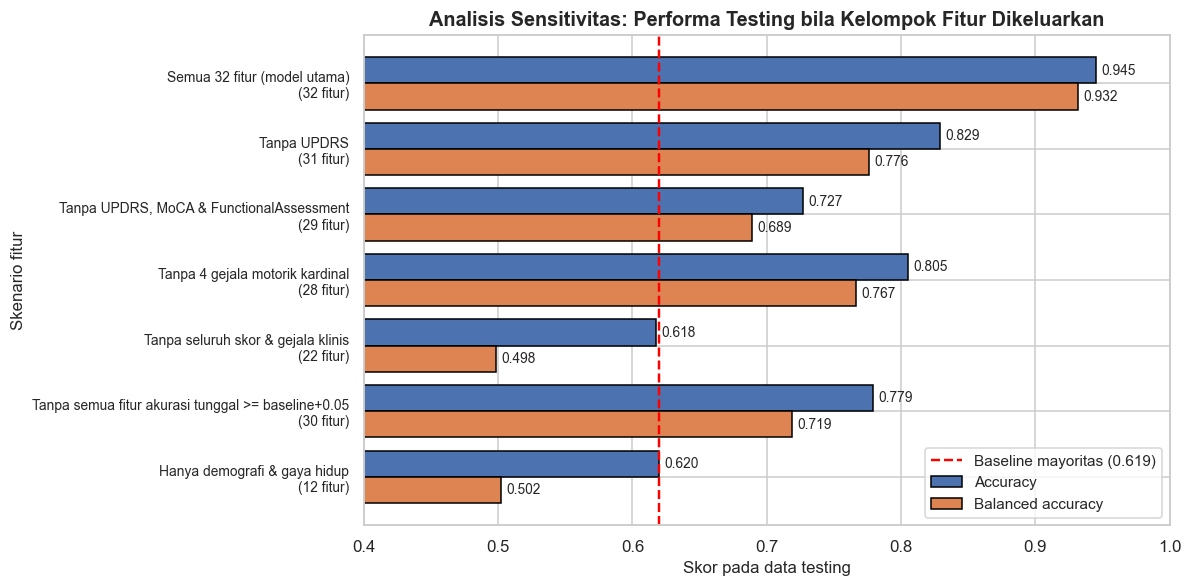

**Interpretasi:** model dengan seluruh fitur mencapai accuracy **0.9454** (balanced accuracy 0.9318). Membuang `UPDRS` saja mengubah accuracy menjadi **0.8290** (-0.1164); membuang ketiga skor penilaian klinis menjadi **0.7268** (-0.2185); membuang 4 gejala motorik kardinal menjadi **0.8052** (-0.1401).

Setelah **seluruh skor dan gejala klinis** dibuang (tersisa 22 fitur), accuracy **0.6176** (balanced accuracy 0.4981, recall kelas terlemah 0.000); pada skenario paling terbatas (demografi & gaya hidup, 12 fitur) accuracy **0.6200** (balanced accuracy 0.5024) dibandingkan baseline 0.6195.

- Ketergantungan pada `UPDRS` **besar** (turun 0.116). Sebagian performa tinggi model utama bertumpu pada satu skor pemeriksaan klinis yang secara konseptual dekat dengan penegakan diagnosis.

- Tanpa pemeriksaan klinis, model **tidak lebih baik dari baseline secara berarti**: faktor demografi dan gaya hidup nyaris tidak membawa sinyal diagnosis pada data ini. Artinya kemampuan prediksi model hampir seluruhnya berasal dari fitur pemeriksaan klinis, yang justru yang paling dekat dengan proses diagnosis.

- Karena tidak ada keterangan waktu pengukuran, **tidak dapat dipastikan** apakah fitur klinis diukur sebelum atau sesudah diagnosis. Maka model utama (semua fitur) paling tepat dibaca sebagai *alat bantu klasifikasi profil klinis*, sedangkan skenario tanpa fitur klinis lebih mendekati pertanyaan *skrining dini*.

In [19]:
score_cols = ["UPDRS", "MoCA", "FunctionalAssessment"]
cardinal_motor = ["Tremor", "Rigidity", "Bradykinesia", "PosturalInstability"]
all_symptoms = cardinal_motor + ["SpeechProblems", "SleepDisorders", "Constipation"]
demo_lifestyle = ["Age", "Gender", "Ethnicity", "EducationLevel", "BMI", "Smoking", "AlcoholConsumption",
                  "PhysicalActivity", "DietQuality", "SleepQuality", "FamilyHistoryParkinsons", "TraumaticBrainInjury"]
n_feat = X.shape[1]

scenarios = {
    f"Semua {n_feat} fitur (model utama)": (),
    "Tanpa UPDRS": ("UPDRS",),
    "Tanpa UPDRS, MoCA & FunctionalAssessment": tuple(score_cols),
    "Tanpa 4 gejala motorik kardinal": tuple(cardinal_motor),
    "Tanpa seluruh skor & gejala klinis": tuple(score_cols + all_symptoms),
    f"Tanpa semua fitur akurasi tunggal >= baseline+{MARGIN_STRONG:.2f}": tuple(strong),
    "Hanya demografi & gaya hidup": tuple(c for c in X.columns if c not in demo_lifestyle),
}
for name_, drop_ in scenarios.items():
    assert all(c in X.columns for c in drop_), f"Ada nama kolom yang salah pada skenario: {name_}"

sens_rows = []
for name_, drop_ in scenarios.items():
    pipe = build_pipeline(drop=drop_, **best_params).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    sens_rows.append({"skenario": name_, "fitur_dibuang": len(drop_), "fitur_tersisa": n_feat - len(drop_),
                      "accuracy": accuracy_score(y_test, pred),
                      "balanced_acc": balanced_accuracy_score(y_test, pred),
                      "macro_f1": f1_score(y_test, pred, average="macro"),
                      "recall_kelas_terlemah": recall_score(y_test, pred, average=None, labels=CLASS_ORDER).min()})
sens = pd.DataFrame(sens_rows)
sens["selisih_vs_utama"] = sens["accuracy"] - sens.loc[0, "accuracy"]
display(sens.round(4))

fig, ax = plt.subplots(figsize=(11, 5.5))
yy = np.arange(len(sens))[::-1]
ax.barh(yy + 0.2, sens["accuracy"], 0.4, color="#4c72b0", edgecolor="black", label="Accuracy")
ax.barh(yy - 0.2, sens["balanced_acc"], 0.4, color="#dd8452", edgecolor="black", label="Balanced accuracy")
ax.axvline(baseline_acc, color="red", ls="--", lw=1.6, label=f"Baseline mayoritas ({baseline_acc:.3f})")
for i_, (a_, b_) in zip(yy, zip(sens["accuracy"], sens["balanced_acc"])):
    ax.text(a_ + 0.004, i_ + 0.2, f"{a_:.3f}", va="center", fontsize=9)
    ax.text(b_ + 0.004, i_ - 0.2, f"{b_:.3f}", va="center", fontsize=9)
ax.set_yticks(yy); ax.set_yticklabels([f"{n_}\n({k_} fitur)" for n_, k_ in zip(sens["skenario"], sens["fitur_tersisa"])], fontsize=9)
ax.set_xlim(0.4, 1.0)
ax.set_title("Analisis Sensitivitas: Performa Testing bila Kelompok Fitur Dikeluarkan")
ax.set_xlabel("Skor pada data testing")
ax.set_ylabel("Skenario fitur")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

sx = sens.set_index("skenario")
k_all, k_upd, k_scores, k_motor, k_clin, k_strong, k_demo = list(sx.index)
a = lambda k: sx.loc[k, "accuracy"]
ba = lambda k: sx.loc[k, "balanced_acc"]
msg = [f"**Interpretasi:** model dengan seluruh fitur mencapai accuracy **{a(k_all):.4f}** (balanced accuracy {ba(k_all):.4f}). "
       f"Membuang `UPDRS` saja mengubah accuracy menjadi **{a(k_upd):.4f}** ({a(k_upd) - a(k_all):+.4f}); membuang ketiga skor penilaian klinis menjadi **{a(k_scores):.4f}** "
       f"({a(k_scores) - a(k_all):+.4f}); membuang 4 gejala motorik kardinal menjadi **{a(k_motor):.4f}** ({a(k_motor) - a(k_all):+.4f}).",
       f"Setelah **seluruh skor dan gejala klinis** dibuang (tersisa {int(sx.loc[k_clin, 'fitur_tersisa'])} fitur), accuracy **{a(k_clin):.4f}** "
       f"(balanced accuracy {ba(k_clin):.4f}, recall kelas terlemah {sx.loc[k_clin, 'recall_kelas_terlemah']:.3f}); pada skenario paling terbatas (demografi & gaya hidup, "
       f"{int(sx.loc[k_demo, 'fitur_tersisa'])} fitur) accuracy **{a(k_demo):.4f}** (balanced accuracy {ba(k_demo):.4f}) dibandingkan baseline {baseline_acc:.4f}."]
drop_upd = a(k_all) - a(k_upd)
if drop_upd >= 0.05:
    msg.append(f"- Ketergantungan pada `UPDRS` **besar** (turun {drop_upd:.3f}). Sebagian performa tinggi model utama bertumpu pada satu skor pemeriksaan klinis yang secara konseptual dekat dengan penegakan diagnosis.")
elif drop_upd >= 0.01:
    msg.append(f"- Ketergantungan pada `UPDRS` **sedang** (turun {drop_upd:.3f}): model masih memanfaatkan fitur lain, tetapi UPDRS memberi kontribusi nyata.")
else:
    msg.append(f"- Ketergantungan pada `UPDRS` **kecil** (turun {drop_upd:.3f}); fitur lain dapat menggantikannya.")
if a(k_demo) <= baseline_acc + 0.03:
    msg.append("- Tanpa pemeriksaan klinis, model **tidak lebih baik dari baseline secara berarti**: faktor demografi dan gaya hidup nyaris tidak membawa sinyal diagnosis pada data ini. "
               "Artinya kemampuan prediksi model hampir seluruhnya berasal dari fitur pemeriksaan klinis, yang justru yang paling dekat dengan proses diagnosis.")
else:
    msg.append("- Tanpa pemeriksaan klinis, model masih melampaui baseline, sehingga demografi, gaya hidup, dan komorbid memberi sinyal tambahan.")
msg.append("- Karena tidak ada keterangan waktu pengukuran, **tidak dapat dipastikan** apakah fitur klinis diukur sebelum atau sesudah diagnosis. "
           "Maka model utama (semua fitur) paling tepat dibaca sebagai *alat bantu klasifikasi profil klinis*, sedangkan skenario tanpa fitur klinis lebih mendekati pertanyaan *skrining dini*.")
display(Markdown("\n\n".join(msg)))

## 15. Feature Importance

`feature_importances_` pada Random Forest adalah **Mean Decrease in Impurity (MDI)**: seberapa besar rata-rata sebuah fitur menurunkan *impurity* (Gini) ketika dipakai untuk memecah simpul di seluruh pohon. Karena `OneHotEncoder` mengubah kolom kategorikal menjadi beberapa kolom biner (mis. `Tremor_0` dan `Tremor_1`), nama fitur diambil dari `get_feature_names_out()` agar urutannya **sesuai dengan** vektor importance, lalu digabung kembali ke fitur asalnya. Nilai importance seluruh fitur berjumlah 1.

**Cara membaca yang benar:** importance menunjukkan **kepentingan prediktif** (fitur mana yang paling banyak dipakai model untuk membedakan kelas), **bukan hubungan sebab-akibat**. Fitur dengan importance tinggi tidak otomatis *menyebabkan* Parkinson; bisa jadi ia hanya merupakan penanda/akibat penyakit atau bagian dari proses diagnosis itu sendiri. MDI juga cenderung memihak fitur numerik dengan banyak nilai unik dan dapat membagi importance di antara fitur-fitur yang saling berkorelasi.

In [20]:
# Ambil nama fitur setelah preprocessing (urutannya sama dengan feature_importances_)
preprocessor_fit = best_pipeline.named_steps["preprocessor"]
rf_model = best_pipeline.named_steps["model"]
feature_names = [n.split("__", 1)[1] for n in preprocessor_fit.get_feature_names_out()]
importances = rf_model.feature_importances_
assert len(feature_names) == len(importances)


def original_feature(name):
    # Petakan nama kolom hasil one-hot (mis. 'Tremor_1') kembali ke fitur asalnya ('Tremor').
    base = name.rsplit("_", 1)[0]
    return base if base in categorical_features else name


fi = (pd.DataFrame({"fitur": feature_names, "importance": importances})
        .sort_values("importance", ascending=False).reset_index(drop=True))
fi["rank"] = fi.index + 1
fi["kumulatif"] = fi["importance"].cumsum()
print(f"Jumlah fitur setelah one-hot encoding: {len(fi)} (dari {X.shape[1]} fitur awal) | total importance = {fi['importance'].sum():.4f}\n")
display(fi[["rank", "fitur", "importance", "kumulatif"]].round(4))

Jumlah fitur setelah one-hot encoding: 53 (dari 32 fitur awal) | total importance = 1.0000



,rank,fitur,importance,kumulatif
0,1,UPDRS,0.3309,0.3309
1,2,FunctionalAssessment,0.0931,0.4240
2,3,MoCA,0.0850,0.5090
3,4,Tremor_1,0.0759,0.5850
4,5,Tremor_0,0.0687,0.6537
5,6,Bradykinesia_1,0.0304,0.6841
6,7,Rigidity_1,0.0297,0.7138
7,8,Bradykinesia_0,0.0297,0.7434
8,9,Rigidity_0,0.0291,0.7726
9,10,PosturalInstability_1,0.0205,0.7931


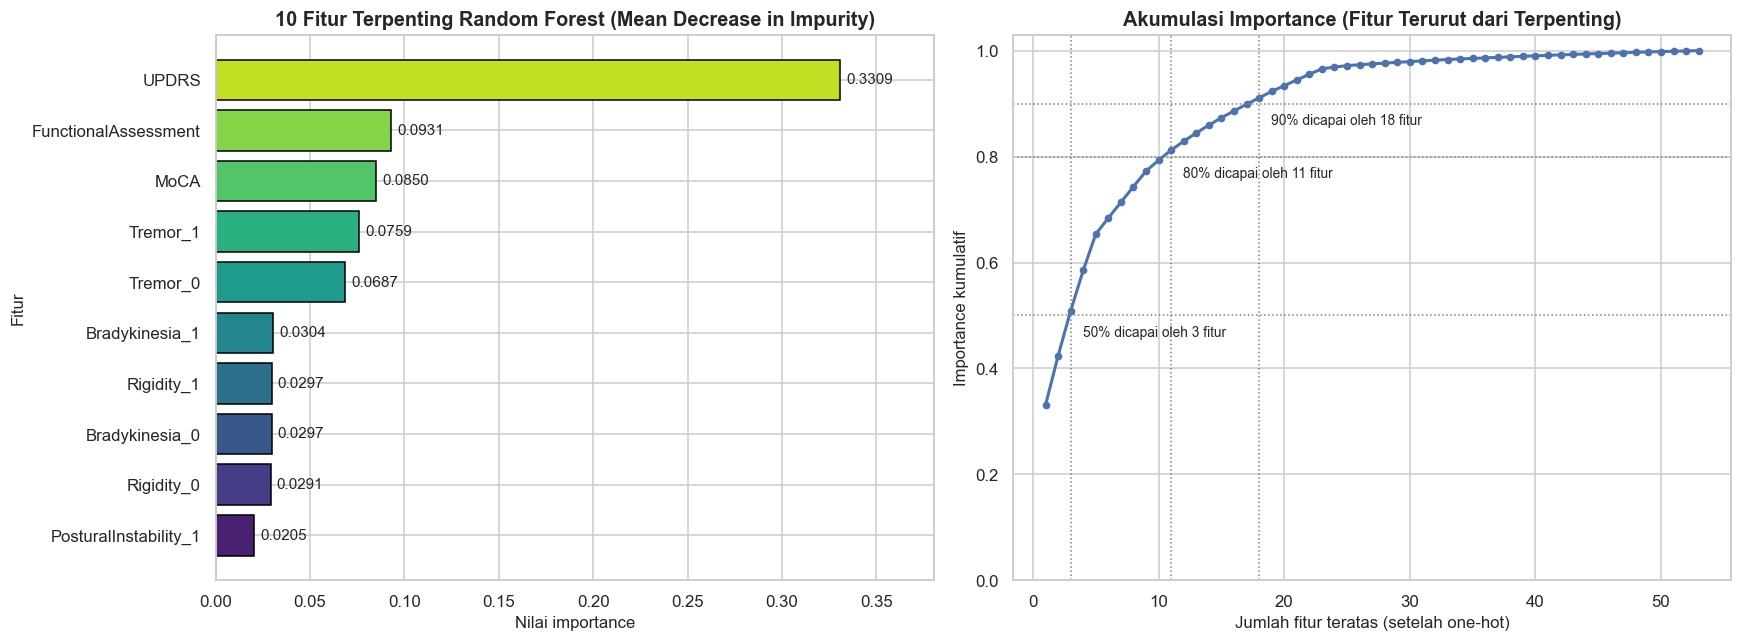

Importance dikelompokkan per fitur asal (32 fitur awal) — 10 teratas:


,importance,kumulatif
fitur_asal,,
UPDRS,0.3309,0.3309
Tremor,0.1447,0.4756
FunctionalAssessment,0.0931,0.5687
MoCA,0.0850,0.6537
Bradykinesia,0.0600,0.7138
Rigidity,0.0588,0.7726
PosturalInstability,0.0397,0.8123
Age,0.0167,0.8290
DietQuality,0.0155,0.8446


Tiga fitur asal teratas menyumbang 56.9%; sepuluh teratas 85.9% dari total importance.


In [21]:
top10 = fi.head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax = axes[0]
colors = sns.color_palette("viridis_r", 10)
ax.barh(top10["fitur"][::-1], top10["importance"][::-1], color=colors[::-1], edgecolor="black")
for i, v in enumerate(top10["importance"][::-1]):
    ax.text(v + top10["importance"].max() * 0.01, i, f"{v:.4f}", va="center", fontsize=10)
ax.set_title("10 Fitur Terpenting Random Forest (Mean Decrease in Impurity)")
ax.set_xlabel("Nilai importance")
ax.set_ylabel("Fitur")
ax.set_xlim(0, top10["importance"].max() * 1.15)

ax = axes[1]
ax.plot(fi["rank"], fi["kumulatif"], marker="o", ms=4, lw=2, color="#4c72b0")
for thr in (0.5, 0.8, 0.9):
    k_thr = int((fi["kumulatif"] >= thr).idxmax()) + 1
    ax.axhline(thr, color="gray", ls=":", lw=1)
    ax.axvline(k_thr, color="gray", ls=":", lw=1)
    ax.annotate(f"{thr:.0%} dicapai oleh {k_thr} fitur", (k_thr, thr), textcoords="offset points", xytext=(8, -14), fontsize=9)
ax.set_title("Akumulasi Importance (Fitur Terurut dari Terpenting)")
ax.set_xlabel("Jumlah fitur teratas (setelah one-hot)")
ax.set_ylabel("Importance kumulatif")
ax.set_ylim(0, 1.03)
plt.tight_layout()
plt.show()

# Agregasi: gabungkan kolom one-hot kembali ke fitur asalnya (mis. Tremor_0 + Tremor_1 -> Tremor)
fi_agg = fi.assign(fitur_asal=fi["fitur"].map(original_feature)).groupby("fitur_asal")["importance"].sum().sort_values(ascending=False)
print(f"Importance dikelompokkan per fitur asal ({X.shape[1]} fitur awal) — 10 teratas:")
agg_table = fi_agg.head(10).round(4).rename("importance").to_frame()
agg_table["kumulatif"] = fi_agg.cumsum().head(10).round(4)
display(agg_table)
print(f"Tiga fitur asal teratas menyumbang {fi_agg.head(3).sum():.1%}; sepuluh teratas {fi_agg.head(10).sum():.1%} dari total importance.")

In [22]:
# Interpretasi 10 fitur teratas: konteks klinis (data) + peringkat importance (hasil model)
clinical_notes = {
    "UPDRS": "Skala penilaian keparahan gejala Parkinson (motorik & non-motorik); skor lebih tinggi = gejala lebih berat. Dekat dengan proses diagnosis.",
    "FunctionalAssessment": "Penilaian kemampuan fungsional aktivitas sehari-hari; pada data ini skor lebih rendah cenderung terkait diagnosis.",
    "MoCA": "Montreal Cognitive Assessment (skrining kognitif); gangguan kognitif dapat menyertai Parkinson.",
    "Tremor": "Tremor (gemetar) istirahat adalah gejala kardinal motorik Parkinson.",
    "Rigidity": "Kekakuan otot; gejala kardinal motorik Parkinson.",
    "Bradykinesia": "Perlambatan gerak; gejala kardinal yang menjadi syarat utama kriteria diagnosis klinis.",
    "PosturalInstability": "Ketidakstabilan postur/keseimbangan; umumnya muncul pada tahap lebih lanjut.",
    "SpeechProblems": "Gangguan bicara (suara pelan, monoton); umum pada Parkinson.",
    "SleepDisorders": "Gangguan tidur (mis. gangguan tidur REM) sering menyertai Parkinson.",
    "Constipation": "Sembelit adalah gejala non-motorik yang sering muncul, kadang sebelum gejala motorik.",
    "Age": "Faktor risiko: kejadian Parkinson meningkat seiring usia.",
    "Gender": "Kode jenis kelamin; insiden Parkinson sedikit berbeda antar jenis kelamin.",
    "Ethnicity": "Kode etnis; interpretasi memerlukan konteks populasi.",
    "EducationLevel": "Kode tingkat pendidikan; berkaitan dengan cadangan kognitif dan skor kognitif.",
    "BMI": "Indeks massa tubuh; penurunan berat badan dapat menyertai penyakit, faktor non-spesifik.",
    "Smoking": "Status merokok; beberapa studi epidemiologi melaporkan asosiasi, interpretasi rumit.",
    "AlcoholConsumption": "Konsumsi alkohol; faktor gaya hidup, hubungan dengan Parkinson tidak tegas.",
    "PhysicalActivity": "Aktivitas fisik; umumnya dikaitkan dengan kesehatan saraf yang lebih baik.",
    "DietQuality": "Kualitas diet; faktor gaya hidup non-spesifik.",
    "SleepQuality": "Kualitas tidur; terganggu pada banyak kondisi, termasuk Parkinson.",
    "FamilyHistoryParkinsons": "Riwayat keluarga Parkinson; faktor risiko genetik.",
    "TraumaticBrainInjury": "Riwayat cedera otak traumatik; dilaporkan sebagai faktor risiko.",
    "Hypertension": "Hipertensi; komorbid vaskular yang non-spesifik.",
    "Diabetes": "Diabetes; komorbid metabolik, dilaporkan berasosiasi dengan risiko neurodegeneratif.",
    "Depression": "Depresi sering menyertai Parkinson (gejala non-motorik).",
    "Stroke": "Riwayat stroke; dapat menimbulkan gejala parkinsonisme vaskular.",
    "SystolicBP": "Tekanan darah sistolik; faktor kardiovaskular non-spesifik.",
    "DiastolicBP": "Tekanan darah diastolik; faktor kardiovaskular non-spesifik.",
    "CholesterolTotal": "Kolesterol total; profil lipid non-spesifik untuk Parkinson.",
    "CholesterolLDL": "Kolesterol LDL; profil lipid non-spesifik untuk Parkinson.",
    "CholesterolHDL": "Kolesterol HDL; profil lipid non-spesifik untuk Parkinson.",
    "CholesterolTriglycerides": "Trigliserida; profil lipid non-spesifik untuk Parkinson.",
}
def note(name):
    base = original_feature(name)
    return clinical_notes.get(base, f"Faktor klinis/komorbid ({base}); interpretasi memerlukan konteks medis.")

interp = top10[["rank", "fitur", "importance"]].copy()
interp["fitur_asal"] = interp["fitur"].map(original_feature)
interp["konteks klinis"] = interp["fitur"].map(note)
pd.set_option("display.max_colwidth", 130)
display(interp.round(4))

clinical_exam = set(score_cols + all_symptoms)               # skor & gejala hasil pemeriksaan klinis
top10_orig = list(dict.fromkeys(interp["fitur_asal"]))       # fitur asal unik di 10 teratas, urut
n_clin = sum(f_ in clinical_exam for f_ in top10_orig)
non_clin = [f_ for f_ in top10_orig if f_ not in clinical_exam]
share_top10 = top10["importance"].sum()
acc_now = accuracy_score(y_test, y_pred_test)

msg = (f"**Ringkasan:** 10 kolom teratas (setelah one-hot) menyumbang **{share_top10:.1%}** dari total importance dan berasal dari **{len(top10_orig)}** fitur asal. "
       f"**{n_clin} dari {len(top10_orig)}** fitur asal tersebut adalah skor/gejala hasil pemeriksaan klinis (`UPDRS`, `MoCA`, `FunctionalAssessment`, atau gejala); "
       f"sisanya ({', '.join('`'+f_+'`' for f_ in non_clin) if non_clin else '-'}) adalah faktor demografi, gaya hidup, komorbid, atau laboratorium. "
       f"Fitur teratas: **`{top10.iloc[0]['fitur']}`** ({top10.iloc[0]['importance']:.4f}); per fitur asal: **`{fi_agg.index[0]}`** ({fi_agg.iloc[0]:.4f}). ")
if fi_agg.iloc[0] > 2 * fi_agg.iloc[1]:
    msg += f"Importance `{fi_agg.index[0]}` lebih dari dua kali fitur peringkat kedua (`{fi_agg.index[1]}`, {fi_agg.iloc[1]:.4f}), jadi model sangat bertumpu pada satu fitur. "
if len(non_clin) > 0 and fi_agg.iloc[len(top10_orig) - 1] < 0.04:
    msg += ("Fitur non-klinis yang masuk 10 besar memiliki importance kecil dan hampir sama besar satu sama lain; pada Random Forest, fitur kontinu bernilai banyak "
            "(mis. kolesterol, diet, alkohol) sering mendapat importance 'dasar' karena banyak titik pemisah yang dicoba, bukan karena benar-benar informatif. ")
msg += ("\n\n**Peringatan interpretasi:** importance = kepentingan **prediktif**, bukan bukti sebab-akibat. Fitur-fitur gejala dan skor klinis dapat tinggi karena merupakan **bagian dari proses diagnosis**, "
        "bukan karena menjadi *penyebab* Parkinson (lihat bagian 8.2, 9.1, dan 14.1). Periksa juga cek stabilitas di bawah.")
display(Markdown(msg))

,rank,fitur,importance,fitur_asal,konteks klinis
0,1,UPDRS,0.3309,UPDRS,Skala penilaian keparahan gejala Parkinson (motorik & non-motorik); skor lebih tinggi = gejala lebih berat. Dekat dengan prose...
1,2,FunctionalAssessment,0.0931,FunctionalAssessment,Penilaian kemampuan fungsional aktivitas sehari-hari; pada data ini skor lebih rendah cenderung terkait diagnosis.
2,3,MoCA,0.0850,MoCA,Montreal Cognitive Assessment (skrining kognitif); gangguan kognitif dapat menyertai Parkinson.
3,4,Tremor_1,0.0759,Tremor,Tremor (gemetar) istirahat adalah gejala kardinal motorik Parkinson.
4,5,Tremor_0,0.0687,Tremor,Tremor (gemetar) istirahat adalah gejala kardinal motorik Parkinson.
5,6,Bradykinesia_1,0.0304,Bradykinesia,Perlambatan gerak; gejala kardinal yang menjadi syarat utama kriteria diagnosis klinis.
6,7,Rigidity_1,0.0297,Rigidity,Kekakuan otot; gejala kardinal motorik Parkinson.
7,8,Bradykinesia_0,0.0297,Bradykinesia,Perlambatan gerak; gejala kardinal yang menjadi syarat utama kriteria diagnosis klinis.
8,9,Rigidity_0,0.0291,Rigidity,Kekakuan otot; gejala kardinal motorik Parkinson.
9,10,PosturalInstability_1,0.0205,PosturalInstability,Ketidakstabilan postur/keseimbangan; umumnya muncul pada tahap lebih lanjut.


**Ringkasan:** 10 kolom teratas (setelah one-hot) menyumbang **79.3%** dari total importance dan berasal dari **7** fitur asal. **7 dari 7** fitur asal tersebut adalah skor/gejala hasil pemeriksaan klinis (`UPDRS`, `MoCA`, `FunctionalAssessment`, atau gejala); sisanya (-) adalah faktor demografi, gaya hidup, komorbid, atau laboratorium. Fitur teratas: **`UPDRS`** (0.3309); per fitur asal: **`UPDRS`** (0.3309). Importance `UPDRS` lebih dari dua kali fitur peringkat kedua (`Tremor`, 0.1447), jadi model sangat bertumpu pada satu fitur. 

**Peringatan interpretasi:** importance = kepentingan **prediktif**, bukan bukti sebab-akibat. Fitur-fitur gejala dan skor klinis dapat tinggi karena merupakan **bagian dari proses diagnosis**, bukan karena menjadi *penyebab* Parkinson (lihat bagian 8.2, 9.1, dan 14.1). Periksa juga cek stabilitas di bawah.

### 15.1 Cek stabilitas feature importance

Importance dari model terbaik dibandingkan dengan **forest referensi** (500 pohon, `max_depth=None`, `random_state=42`). Jika peringkatnya berbeda jauh, berarti peringkat tersebut tidak stabil terhadap pilihan hiperparameter dan tidak layak ditafsirkan terlalu jauh. Perbandingan dilakukan pada tingkat kolom hasil encoding maupun pada tingkat fitur asal.

,model_terbaik,referensi_500_pohon,rank_terbaik,rank_referensi,selisih_rank
UPDRS,0.3309,0.2234,1,1,0
FunctionalAssessment,0.0931,0.0961,2,2,0
MoCA,0.0850,0.0706,3,3,0
Tremor_1,0.0759,0.0435,4,4,0
Tremor_0,0.0687,0.0394,5,5,0
Bradykinesia_1,0.0304,0.0210,6,19,13
Rigidity_1,0.0297,0.0203,7,20,13
Bradykinesia_0,0.0297,0.0191,8,21,13
Rigidity_0,0.0291,0.0216,9,18,9
PosturalInstability_1,0.0205,0.0150,10,23,13


Perbandingan peringkat pada tingkat fitur asal (10 teratas model terbaik):


,model_terbaik,referensi_500_pohon,rank_terbaik,rank_referensi
UPDRS,0.3309,0.2234,1,1
Tremor,0.1447,0.0829,2,3
FunctionalAssessment,0.0931,0.0961,3,2
MoCA,0.0850,0.0706,4,4
Bradykinesia,0.0600,0.0401,5,6
Rigidity,0.0588,0.0419,6,5
PosturalInstability,0.0397,0.0302,7,7
Age,0.0167,0.0286,8,9
DietQuality,0.0155,0.0295,9,8
BMI,0.0148,0.0264,10,14


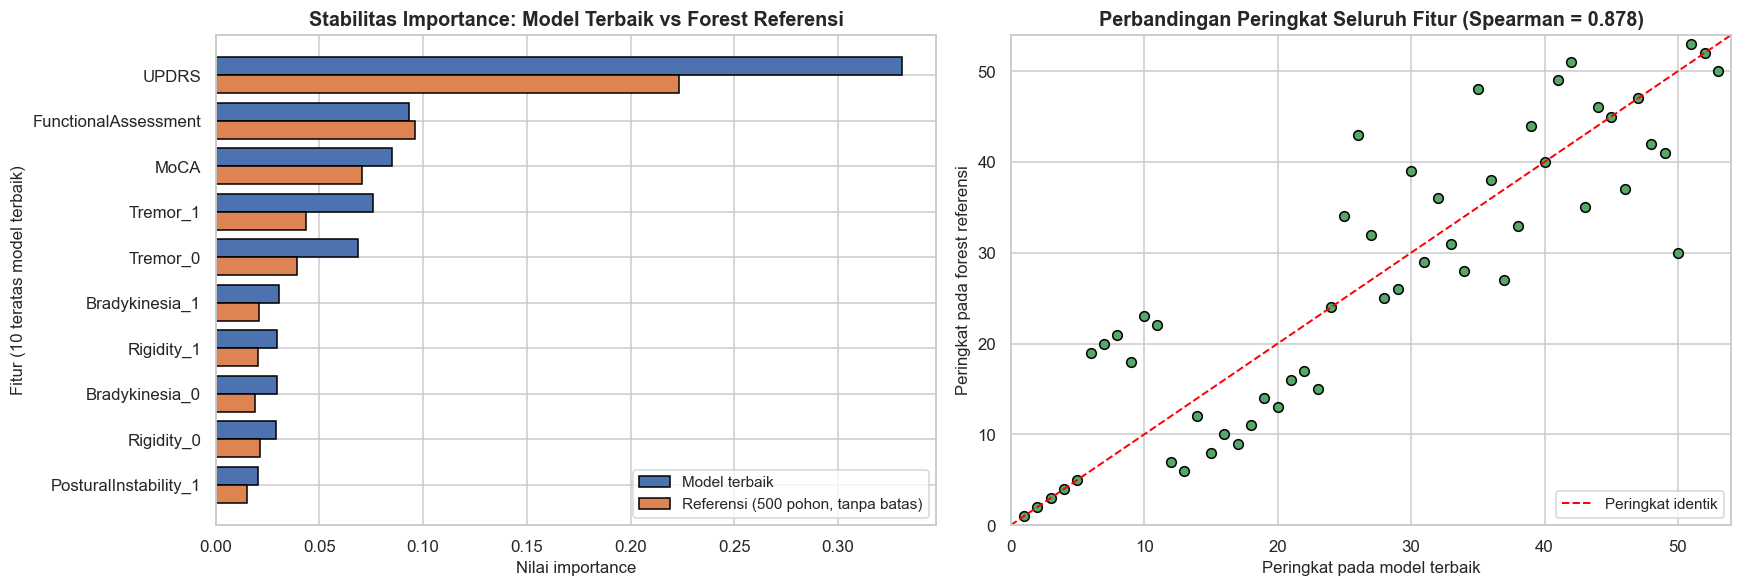

**Hasil:** 5 dari 10 kolom teratas sama pada kedua model (pada tingkat fitur asal: 9 dari 10); korelasi peringkat seluruh kolom (Spearman) = **0.878**. Peringkat **cukup berubah** antar konfigurasi: terutama fitur-fitur di tengah/bawah daftar (importance kecil dan berdekatan) tidak boleh ditafsirkan sebagai urutan pasti. Fitur teratas (`UPDRS`) tetap berada di posisi pertama pada kedua model.

In [23]:
ref_pipe = build_pipeline(n_estimators=500, max_depth=None).fit(X_train, y_train)
ref_names = [n.split("__", 1)[1] for n in ref_pipe.named_steps["preprocessor"].get_feature_names_out()]
ref_fi = pd.Series(ref_pipe.named_steps["model"].feature_importances_, index=ref_names)
cur_fi = pd.Series(importances, index=feature_names)

cmp_df = pd.DataFrame({"model_terbaik": cur_fi, "referensi_500_pohon": ref_fi})
cmp_df["rank_terbaik"] = cmp_df["model_terbaik"].rank(ascending=False, method="first").astype(int)
cmp_df["rank_referensi"] = cmp_df["referensi_500_pohon"].rank(ascending=False, method="first").astype(int)
cmp_df["selisih_rank"] = cmp_df["rank_referensi"] - cmp_df["rank_terbaik"]
top_cmp = cmp_df.sort_values("model_terbaik", ascending=False).head(10)
display(top_cmp.round(4))

overlap = len(set(cur_fi.nlargest(10).index) & set(ref_fi.nlargest(10).index))
rank_corr = cmp_df["model_terbaik"].rank().corr(cmp_df["referensi_500_pohon"].rank())   # korelasi peringkat (Spearman)

# Perbandingan pada tingkat fitur asal
agg_cur = cur_fi.groupby(cur_fi.index.map(original_feature)).sum().sort_values(ascending=False)
agg_ref = ref_fi.groupby(ref_fi.index.map(original_feature)).sum().sort_values(ascending=False)
overlap_agg = len(set(agg_cur.head(10).index) & set(agg_ref.head(10).index))
agg_cmp = pd.DataFrame({"model_terbaik": agg_cur, "referensi_500_pohon": agg_ref}).loc[agg_cur.index]
agg_cmp["rank_terbaik"] = np.arange(1, len(agg_cmp) + 1)
agg_cmp["rank_referensi"] = agg_cmp["referensi_500_pohon"].rank(ascending=False, method="first").astype(int)
print("Perbandingan peringkat pada tingkat fitur asal (10 teratas model terbaik):")
display(agg_cmp.head(10).round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
yy = np.arange(len(top_cmp))[::-1]
ax.barh(yy + 0.2, top_cmp["model_terbaik"], 0.4, label="Model terbaik", color="#4c72b0", edgecolor="black")
ax.barh(yy - 0.2, top_cmp["referensi_500_pohon"], 0.4, label="Referensi (500 pohon, tanpa batas)", color="#dd8452", edgecolor="black")
ax.set_yticks(yy); ax.set_yticklabels(top_cmp.index)
ax.set_title("Stabilitas Importance: Model Terbaik vs Forest Referensi")
ax.set_xlabel("Nilai importance")
ax.set_ylabel("Fitur (10 teratas model terbaik)")
ax.legend(loc="lower right")

ax = axes[1]
ax.scatter(cmp_df["rank_terbaik"], cmp_df["rank_referensi"], s=40, color="#55a868", edgecolor="black")
lim = len(cmp_df) + 1
ax.plot([0, lim], [0, lim], color="red", ls="--", lw=1.3, label="Peringkat identik")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f"Perbandingan Peringkat Seluruh Fitur (Spearman = {rank_corr:.3f})")
ax.set_xlabel("Peringkat pada model terbaik")
ax.set_ylabel("Peringkat pada forest referensi")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Hasil:** {overlap} dari 10 kolom teratas sama pada kedua model (pada tingkat fitur asal: {overlap_agg} dari 10); "
    f"korelasi peringkat seluruh kolom (Spearman) = **{rank_corr:.3f}**. "
    + ("Peringkat **relatif stabil**, namun tetap dibaca sebagai kepentingan prediktif."
       if overlap >= 8 and rank_corr >= 0.9 else
       "Peringkat **cukup berubah** antar konfigurasi: terutama fitur-fitur di tengah/bawah daftar (importance kecil dan berdekatan) tidak boleh ditafsirkan sebagai urutan pasti. "
       f"Fitur teratas (`{agg_cur.index[0]}`) " + ("tetap berada di posisi pertama pada kedua model." if agg_cur.index[0] == agg_ref.index[0] else "tidak berada di posisi pertama pada kedua model."))))

## 16. Evaluasi Akhir Model

Model terbaik dievaluasi pada **data testing** yang tidak dipakai untuk pelatihan. Karena kelas tidak seimbang, ditampilkan:

- **Accuracy** dan **Balanced Accuracy** (rata-rata recall per kelas — tidak terpengaruh ukuran kelas).
- **Precision, Recall, F1-Score** per kelas.
- **Macro average** (semua kelas berbobot sama; sensitif terhadap kelas yang lebih kecil) dan **Weighted average** (berbobot jumlah sampel; lebih dipengaruhi kelas mayoritas).
- **Confusion Matrix** (jumlah dan proporsi per baris).

Seluruh angka berasal langsung dari hasil eksekusi model, tanpa penyesuaian.

In [24]:
# Ringkasan metrik global
summary = {
    "accuracy": accuracy_score(y_test, y_pred_test),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred_test),
    "precision_macro": precision_score(y_test, y_pred_test, average="macro"),
    "recall_macro": recall_score(y_test, y_pred_test, average="macro"),
    "f1_macro": f1_score(y_test, y_pred_test, average="macro"),
    "precision_weighted": precision_score(y_test, y_pred_test, average="weighted"),
    "recall_weighted": recall_score(y_test, y_pred_test, average="weighted"),
    "f1_weighted": f1_score(y_test, y_pred_test, average="weighted"),
}
display(pd.Series(summary, name="nilai").round(4).to_frame())

print("Classification Report (data testing):\n")
print(classification_report(y_test, y_pred_test, labels=CLASS_ORDER,
                            target_names=[CLASS_NAMES[c] for c in CLASS_ORDER], digits=4))

# Tabel per kelas (precision, recall, F1, support)
p_cls, r_cls, f_cls, s_cls = precision_recall_fscore_support(y_test, y_pred_test, labels=CLASS_ORDER, zero_division=0)
per_class = pd.DataFrame({"precision": p_cls, "recall": r_cls, "f1-score": f_cls, "support": s_cls},
                         index=[f"{c} = {CLASS_NAMES[c]}" for c in CLASS_ORDER])
display(per_class.round(4))

,nilai
accuracy,0.9454
balanced_accuracy,0.9318
precision_macro,0.9535
recall_macro,0.9318
f1_macro,0.9407
precision_weighted,0.9474
recall_weighted,0.9454
f1_weighted,0.9447


Classification Report (data testing):

                              precision    recall  f1-score   support

Tidak Terdiagnosis Parkinson     0.9790    0.8750    0.9241       160
      Terdiagnosis Parkinson     0.9281    0.9885    0.9573       261

                    accuracy                         0.9454       421
                   macro avg     0.9535    0.9318    0.9407       421
                weighted avg     0.9474    0.9454    0.9447       421



,precision,recall,f1-score,support
0 = Tidak Terdiagnosis Parkinson,0.9790,0.8750,0.9241,160
1 = Terdiagnosis Parkinson,0.9281,0.9885,0.9573,261


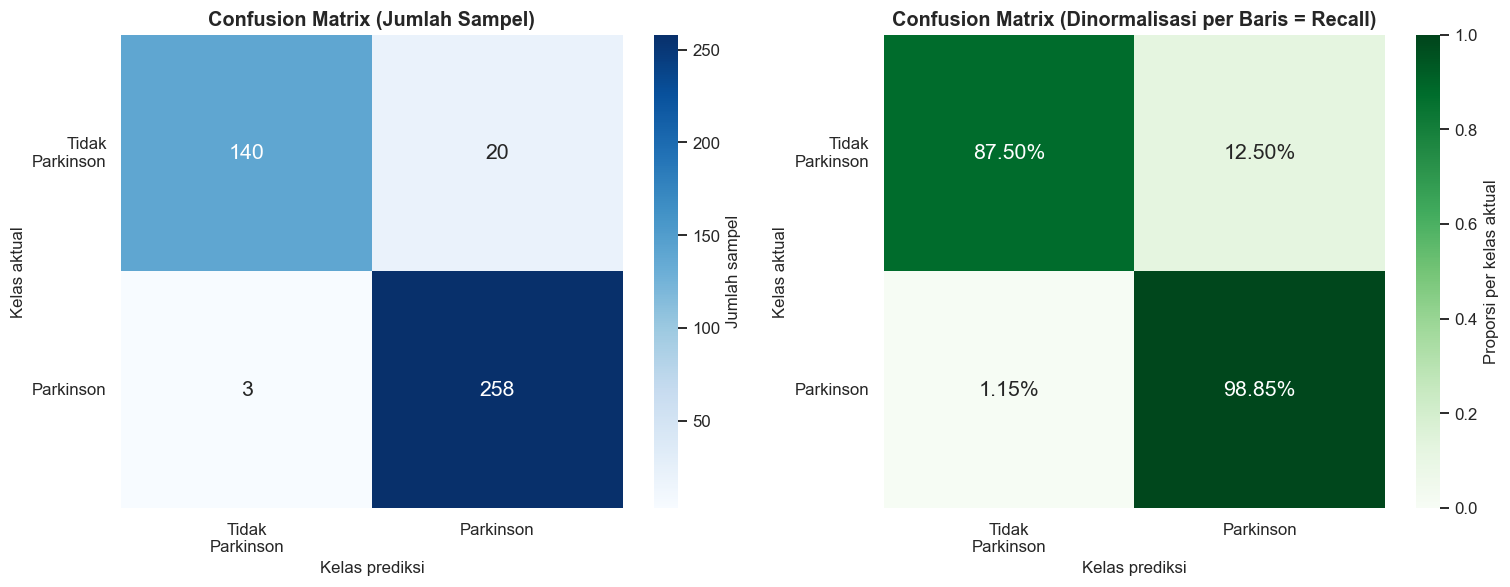

### Analisis otomatis evaluasi
- Accuracy **0.9454** vs baseline kelas mayoritas **0.6195** (selisih +0.3259); balanced accuracy **0.9318**; macro F1 **0.9407** vs weighted F1 **0.9447**.
- Recall per kelas: Tidak Parkinson = 0.875, Parkinson = 0.989.
- **Sensitivitas** (recall kelas Parkinson) = 0.989; **spesifisitas** (recall kelas tidak Parkinson) = 0.875; PPV (precision Parkinson) = 0.928; NPV = 0.979.
- Kelas dengan recall terendah: **Tidak Terdiagnosis Parkinson** (recall 0.875, F1 0.924, support 160).
- Total salah klasifikasi: **23** dari 421 (5.5%): **3 false negative** (pasien Parkinson diprediksi tidak Parkinson) dan **20 false positive** (tanpa Parkinson diprediksi Parkinson).
- Kesalahan lebih banyak berupa *false positive*: lebih banyak pasien tanpa diagnosis yang salah ditandai Parkinson.

In [25]:
# Confusion matrix: jumlah (kiri) dan proporsi per baris = recall per kelas (kanan)
cm = confusion_matrix(y_test, y_pred_test, labels=CLASS_ORDER)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
labels_short = [SHORT_LABEL[c] for c in CLASS_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_short, yticklabels=labels_short,
            annot_kws={"size": 14}, cbar_kws={"label": "Jumlah sampel"}, ax=axes[0])
axes[0].set_title("Confusion Matrix (Jumlah Sampel)")
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens", xticklabels=labels_short, yticklabels=labels_short,
            vmin=0, vmax=1, annot_kws={"size": 14}, cbar_kws={"label": "Proporsi per kelas aktual"}, ax=axes[1])
axes[1].set_title("Confusion Matrix (Dinormalisasi per Baris = Recall)")
for ax in axes:
    ax.set_xlabel("Kelas prediksi")
    ax.set_ylabel("Kelas aktual")
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

# ----- Analisis otomatis -----
tn, fp, fn, tp = (int(v) for v in cm.ravel())          # kelas 0 = negatif, kelas 1 = positif (terdiagnosis Parkinson)
sensitivity, specificity = tp / (tp + fn), tn / (tn + fp)
ppv, npv = tp / (tp + fp), tn / (tn + fn)
recall_per_class = pd.Series(r_cls, index=CLASS_ORDER)
f1_per_class = pd.Series(f_cls, index=CLASS_ORDER)
weakest = recall_per_class.idxmin()
n_err = fp + fn
perfect = n_err == 0

lines = ["### Analisis otomatis evaluasi",
         f"- Accuracy **{summary['accuracy']:.4f}** vs baseline kelas mayoritas **{baseline_acc:.4f}** (selisih {summary['accuracy'] - baseline_acc:+.4f}); "
         f"balanced accuracy **{summary['balanced_accuracy']:.4f}**; macro F1 **{summary['f1_macro']:.4f}** vs weighted F1 **{summary['f1_weighted']:.4f}**.",
         "- Recall per kelas: " + ", ".join(f"{flat(SHORT_LABEL[c])} = {v:.3f}" for c, v in recall_per_class.items()) + ".",
         f"- **Sensitivitas** (recall kelas Parkinson) = {sensitivity:.3f}; **spesifisitas** (recall kelas tidak Parkinson) = {specificity:.3f}; "
         f"PPV (precision Parkinson) = {ppv:.3f}; NPV = {npv:.3f}."]
if perfect:
    lines.append(f"- **Tidak ada satu pun salah klasifikasi** dari {int(cm.sum())} sampel uji.")
else:
    lines += [f"- Kelas dengan recall terendah: **{CLASS_NAMES[weakest]}** (recall {recall_per_class.min():.3f}, F1 {f1_per_class[weakest]:.3f}, support {int(per_class.loc[f'{weakest} = {CLASS_NAMES[weakest]}', 'support'])}).",
              f"- Total salah klasifikasi: **{n_err}** dari {int(cm.sum())} ({n_err / cm.sum():.1%}): **{fn} false negative** (pasien Parkinson diprediksi tidak Parkinson) "
              f"dan **{fp} false positive** (tanpa Parkinson diprediksi Parkinson).",
              ("- Kesalahan lebih banyak berupa *false negative*: pasien terdiagnosis yang terlewat lebih banyak daripada yang salah ditandai." if fn > fp else
               "- Kesalahan lebih banyak berupa *false positive*: lebih banyak pasien tanpa diagnosis yang salah ditandai Parkinson." if fp > fn else
               "- Jumlah *false negative* dan *false positive* sama.")]
display(Markdown("\n".join(lines)))

## 17. Business Insight

Bagian ini menafsirkan hasil dalam konteks kesehatan. Seluruh poin disusun otomatis dari hasil eksekusi agar selalu konsisten dengan angka yang sebenarnya; hanya penegasan pada bagian akhir yang bersifat umum.

In [26]:
top5_agg = ", ".join(f"`{n_}`" for n_ in fi_agg.head(5).index)
med = df.groupby(TARGET)[["UPDRS", "MoCA", "FunctionalAssessment"]].median()
rng = df.groupby(TARGET)["UPDRS"].agg(["min", "max"])
tremor_rate = df.groupby("Tremor")[TARGET].mean()
r_best_depth = results_B.set_index("max_depth").loc[best_depth_label]

bi = ["**1. Fitur apa yang paling berpengaruh dalam klasifikasi?**",
      f"Lima fitur asal dengan importance tertinggi: {top5_agg}. Fitur teratas `{fi_agg.index[0]}` memiliki importance {fi_agg.iloc[0]:.4f} "
      f"({fi_agg.iloc[0] / fi_agg.sum():.1%} dari total). Fitur-fitur ini berasal dari pemeriksaan klinis (skor dan gejala) yang secara konseptual dekat dengan proses diagnosis. "
      f"Karena itu (bagian 8.2, 9.1, 14.1, dan 15.1), peringkat importance **bukan temuan faktor risiko baru** dan **bukan bukti sebab-akibat**.",
      "",
      "**2. Bagaimana model membedakan pasien dengan dan tanpa diagnosis Parkinson?**",
      f"Pada data, median UPDRS pasien terdiagnosis **{med.loc[1, 'UPDRS']:.1f}** vs **{med.loc[0, 'UPDRS']:.1f}** pada yang tidak; median MoCA {med.loc[1, 'MoCA']:.1f} vs {med.loc[0, 'MoCA']:.1f}; "
      f"median FunctionalAssessment {med.loc[1, 'FunctionalAssessment']:.2f} vs {med.loc[0, 'FunctionalAssessment']:.2f}. Proporsi terdiagnosis pada pasien bertremor {tremor_rate[1]:.1%} vs {tremor_rate[0]:.1%} tanpa tremor. "
      f"Namun rentang UPDRS kedua kelas saling tumpang tindih lebar ({rng.loc[0, 'min']:.1f}–{rng.loc[0, 'max']:.1f} vs {rng.loc[1, 'min']:.1f}–{rng.loc[1, 'max']:.1f}), "
      f"sehingga model menggabungkan banyak fitur dan interaksinya. Pada data uji model mencapai sensitivitas {sensitivity:.3f} dan spesifisitas {specificity:.3f}.",
      "",
      "**3. Bagaimana pengaruh jumlah pohon terhadap performa?**",
      f"Akurasi testing {results_A.iloc[0]['test_acc']:.4f} (10 pohon) menjadi {results_A.iloc[-1]['test_acc']:.4f} (500 pohon); nilai tertinggi {max_acc_A:.4f} pada n = {argmax_n}. "
      f"Log loss testing turun dari {results_A.iloc[0]['test_log_loss']:.4f} ke {results_A['test_log_loss'].min():.4f} (terendah), sementara waktu pelatihan naik sekitar "
      f"{results_A.iloc[-1]['fit_sec'] / results_A.iloc[0]['fit_sec']:.1f}x. Terpilih `n_estimators = {best_n}`. Jumlah pohon yang kecil memberi estimasi kurang stabil; setelah jumlah tertentu perbaikannya kecil (*diminishing returns*).",
      "",
      "**4. Bagaimana pengaruh kedalaman pohon?**",
      f"`max_depth=3` memberi accuracy {shallow['test_acc']:.4f} dengan balanced accuracy {shallow['test_bal_acc']:.4f} (kapasitas kurang); kedalaman 10 memberi {rb_idx.loc['10', 'test_acc']:.4f}; "
      f"tanpa batas {deep['test_acc']:.4f}. Terpilih `max_depth = {best_depth_label}` (accuracy {r_best_depth['test_acc']:.4f}, gap {r_best_depth['gap']:.4f}).",
      "",
      "**5. Apakah terdapat indikasi overfitting?**",
      (f"Ya, pada `max_depth` = {', '.join(over_labels)} gap besar disertai akurasi testing lebih rendah dari yang terbaik." if over_labels else
       f"Model terpilih (`max_depth = {best_depth_label}`) memiliki akurasi training {accuracy_score(y_train, y_pred_train):.4f} vs testing {summary['accuracy']:.4f} "
       f"(gap {accuracy_score(y_train, y_pred_train) - summary['accuracy']:+.4f}). Model yang lebih dalam (`max_depth` 20/`None`) mencapai akurasi training {deep['train_acc']:.4f} "
       f"(gap {deep['gap']:.4f}, efek *bootstrap* Random Forest) tetapi akurasi testingnya ({deep['test_acc']:.4f}) tidak lebih tinggi dari model terpilih "
       f"({r_best_depth['test_acc']:.4f}; selisih {r_best_depth['test_acc'] - deep['test_acc']:+.4f}). Jadi pohon yang lebih dalam hanya menambah kompleksitas tanpa manfaat pada data uji; "
       f"tidak ada indikasi overfitting yang merugikan secara berarti, dan `max_depth=3` justru menunjukkan *underfitting*."),
      "",
      "**6. Bagaimana hasil evaluasi model?**",
      f"Accuracy {summary['accuracy']:.4f} (baseline {baseline_acc:.4f}), balanced accuracy {summary['balanced_accuracy']:.4f}, macro F1 {summary['f1_macro']:.4f}; "
      f"{fn} false negative dan {fp} false positive dari {int(cm.sum())} sampel uji."]
display(Markdown("\n".join(bi)))

# Poin 7-8: keterbatasan (angka diambil dari hasil) dan potensi penerapan
n_test_min = int(per_class["support"].min())
lim = ["**7. Apa keterbatasan dataset dan model?**",
       f"- Distribusi banyak fitur kontinu hampir **seragam** ({n_uniform} dari {len(ks_df)} fitur bernilai banyak, bagian 5), yang tidak lazim pada data klinis nyata; dataset mungkin dibangkitkan secara simulasi dan **belum divalidasi secara eksternal**.",
       f"- Fitur pemeriksaan klinis (`UPDRS`, gejala, `MoCA`, `FunctionalAssessment`) berpotensi dekat dengan proses diagnosis; tanpa waktu pengukuran, urutan sebab-akibat tidak dapat diverifikasi. Tanpa seluruh skor dan gejala klinis, accuracy turun ke {a(k_clin):.4f} (baseline {baseline_acc:.4f}).",
       f"- Kelas yang lebih kecil ({CLASS_NAMES[minority]}) hanya memiliki {n_test_min} sampel uji, sehingga estimasi recall-nya kurang stabil.",
       "- Pemilihan hiperparameter memakai data testing (sesuai ketentuan tugas), sehingga estimasi akhir cenderung optimis; belum dipakai *cross-validation*.",
       "- Data hanya satu kali pengukuran per pasien (cross-sectional), tanpa perkembangan penyakit dari waktu ke waktu.",
       "",
       "**8. Bagaimana potensi penerapan model dalam sistem pendukung analisis kesehatan?**",
       "Model dapat menjadi komponen *pendukung analisis* di dasbor kesehatan: memberi **skor kemungkinan** dan menandai profil pasien untuk ditinjau tenaga medis, "
       "memprioritaskan antrean evaluasi neurologis, serta menjadi bahan pembelajaran alur *machine learning* yang benar (pipeline, split terstratifikasi, evaluasi per kelas, pemeriksaan leakage). "
       "Penerapan nyata memerlukan data klinis nyata berlabel independen, validasi eksternal, kalibrasi probabilitas, dan evaluasi etika serta regulasi."]
display(Markdown("\n".join(lim)))

**1. Fitur apa yang paling berpengaruh dalam klasifikasi?**
Lima fitur asal dengan importance tertinggi: `UPDRS`, `Tremor`, `FunctionalAssessment`, `MoCA`, `Bradykinesia`. Fitur teratas `UPDRS` memiliki importance 0.3309 (33.1% dari total). Fitur-fitur ini berasal dari pemeriksaan klinis (skor dan gejala) yang secara konseptual dekat dengan proses diagnosis. Karena itu (bagian 8.2, 9.1, 14.1, dan 15.1), peringkat importance **bukan temuan faktor risiko baru** dan **bukan bukti sebab-akibat**.

**2. Bagaimana model membedakan pasien dengan dan tanpa diagnosis Parkinson?**
Pada data, median UPDRS pasien terdiagnosis **120.2** vs **48.6** pada yang tidak; median MoCA 13.4 vs 18.2; median FunctionalAssessment 4.15 vs 6.22. Proporsi terdiagnosis pada pasien bertremor 77.2% vs 50.3% tanpa tremor. Namun rentang UPDRS kedua kelas saling tumpang tindih lebar (0.0–198.9 vs 0.2–199.0), sehingga model menggabungkan banyak fitur dan interaksinya. Pada data uji model mencapai sensitivitas 0.989 dan spesifisitas 0.875.

**3. Bagaimana pengaruh jumlah pohon terhadap performa?**
Akurasi testing 0.9050 (10 pohon) menjadi 0.9430 (500 pohon); nilai tertinggi 0.9430 pada n = 300. Log loss testing turun dari 0.4739 ke 0.3003 (terendah), sementara waktu pelatihan naik sekitar 4.9x. Terpilih `n_estimators = 500`. Jumlah pohon yang kecil memberi estimasi kurang stabil; setelah jumlah tertentu perbaikannya kecil (*diminishing returns*).

**4. Bagaimana pengaruh kedalaman pohon?**
`max_depth=3` memberi accuracy 0.7957 dengan balanced accuracy 0.7325 (kapasitas kurang); kedalaman 10 memberi 0.9406; tanpa batas 0.9430. Terpilih `max_depth = 5` (accuracy 0.9454, gap -0.0012).

**5. Apakah terdapat indikasi overfitting?**
Model terpilih (`max_depth = 5`) memiliki akurasi training 0.9442 vs testing 0.9454 (gap -0.0012). Model yang lebih dalam (`max_depth` 20/`None`) mencapai akurasi training 1.0000 (gap 0.0570, efek *bootstrap* Random Forest) tetapi akurasi testingnya (0.9430) tidak lebih tinggi dari model terpilih (0.9454; selisih +0.0024). Jadi pohon yang lebih dalam hanya menambah kompleksitas tanpa manfaat pada data uji; tidak ada indikasi overfitting yang merugikan secara berarti, dan `max_depth=3` justru menunjukkan *underfitting*.

**6. Bagaimana hasil evaluasi model?**
Accuracy 0.9454 (baseline 0.6195), balanced accuracy 0.9318, macro F1 0.9407; 3 false negative dan 20 false positive dari 421 sampel uji.

**7. Apa keterbatasan dataset dan model?**
- Distribusi banyak fitur kontinu hampir **seragam** (12 dari 12 fitur bernilai banyak, bagian 5), yang tidak lazim pada data klinis nyata; dataset mungkin dibangkitkan secara simulasi dan **belum divalidasi secara eksternal**.
- Fitur pemeriksaan klinis (`UPDRS`, gejala, `MoCA`, `FunctionalAssessment`) berpotensi dekat dengan proses diagnosis; tanpa waktu pengukuran, urutan sebab-akibat tidak dapat diverifikasi. Tanpa seluruh skor dan gejala klinis, accuracy turun ke 0.6176 (baseline 0.6195).
- Kelas yang lebih kecil (Tidak Terdiagnosis Parkinson) hanya memiliki 160 sampel uji, sehingga estimasi recall-nya kurang stabil.
- Pemilihan hiperparameter memakai data testing (sesuai ketentuan tugas), sehingga estimasi akhir cenderung optimis; belum dipakai *cross-validation*.
- Data hanya satu kali pengukuran per pasien (cross-sectional), tanpa perkembangan penyakit dari waktu ke waktu.

**8. Bagaimana potensi penerapan model dalam sistem pendukung analisis kesehatan?**
Model dapat menjadi komponen *pendukung analisis* di dasbor kesehatan: memberi **skor kemungkinan** dan menandai profil pasien untuk ditinjau tenaga medis, memprioritaskan antrean evaluasi neurologis, serta menjadi bahan pembelajaran alur *machine learning* yang benar (pipeline, split terstratifikasi, evaluasi per kelas, pemeriksaan leakage). Penerapan nyata memerlukan data klinis nyata berlabel independen, validasi eksternal, kalibrasi probabilitas, dan evaluasi etika serta regulasi.

> ⚠️ **Model ini adalah alat bantu penelitian dan edukasi, BUKAN pengganti diagnosis atau keputusan dokter.** Diagnosis Parkinson hanya dapat ditegakkan oleh tenaga medis melalui pemeriksaan klinis menyeluruh.

## 18. Kesimpulan

Kesimpulan di bawah ini disusun otomatis dari hasil eksekusi di atas, sehingga selalu sesuai dengan angka yang sebenarnya.

In [27]:
top3 = ", ".join(f"`{n_}`" for n_ in fi_agg.head(3).index)
items = []
items.append(f"**Penerapan Random Forest:** `RandomForestClassifier` dalam `Pipeline` (imputasi median / modus + one-hot encoding) pada {df.shape[0]:,} pasien, {n_feat} fitur "
             f"(`PatientID` dan `DoctorInCharge` dibuang), split 80:20 terstratifikasi; kelas mayoritas ({CLASS_NAMES[majority]}) = {baseline_acc:.4f}.")
items.append(f"**Parameter terbaik:** `n_estimators = {best_n}` dan `max_depth = {best_depth_label}`. Jumlah pohon: akurasi testing {results_A.iloc[0]['test_acc']:.4f} (10 pohon) → {results_A.iloc[-1]['test_acc']:.4f} (500 pohon). "
             f"Kedalaman: `max_depth=3` {shallow['test_acc']:.4f} (underfitting), kedalaman 5 {rb_idx.loc['5', 'test_acc']:.4f}, kedalaman 10 {rb_idx.loc['10', 'test_acc']:.4f}, tanpa batas {deep['test_acc']:.4f}; "
             f"gap train–test maksimum {results_B['gap'].max():.4f}"
             + (" dan terdapat indikasi overfitting merugikan." if over_labels else
                f" pada pohon dalam, tetapi pohon yang lebih dalam tidak meningkatkan akurasi testing (tanpa batas {deep['test_acc']:.4f} vs terpilih {r_best_depth['test_acc']:.4f}), sehingga tidak ada overfitting yang merugikan secara berarti."))
items.append(f"**Performa model final:** accuracy **{summary['accuracy']:.4f}**, balanced accuracy **{summary['balanced_accuracy']:.4f}**, macro F1 **{summary['f1_macro']:.4f}**, "
             f"weighted F1 **{summary['f1_weighted']:.4f}** (baseline {baseline_acc:.4f}); sensitivitas {sensitivity:.3f}, spesifisitas {specificity:.3f}; {fn} false negative dan {fp} false positive dari {int(cm.sum())} sampel uji.")
items.append(f"**Fitur terpenting:** {top3} (kepentingan prediktif, bukan sebab-akibat). Stabilitas: {overlap}/10 kolom teratas sama dengan forest referensi 500 pohon (Spearman {rank_corr:.2f}).")
items.append(f"**Analisis sensitivitas:** membuang `UPDRS` mengubah accuracy dari {a(k_all):.4f} ke {a(k_upd):.4f}; membuang seluruh skor dan gejala klinis menjadi {a(k_clin):.4f}; "
             f"hanya demografi & gaya hidup {a(k_demo):.4f} (baseline {baseline_acc:.4f}). Tidak ada fitur tunggal yang menentukan label secara deterministik "
             f"(akurasi fitur tunggal terbaik `{single_feat.iloc[0]['fitur']}` = {single_feat.iloc[0]['akurasi_fitur_tunggal']:.3f}), tetapi performa model bergantung pada fitur pemeriksaan klinis.")
items.append("**Keterbatasan:** distribusi fitur yang hampir seragam mengindikasikan data kemungkinan simulasi; waktu pengukuran fitur klinis tidak diketahui; hiperparameter dipilih dengan data testing; "
             "satu kali split tanpa cross-validation; belum ada validasi eksternal. Model adalah **alat bantu penelitian/edukasi**, bukan pengganti diagnosis atau keputusan dokter.")
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(items, 1))))

1. **Penerapan Random Forest:** `RandomForestClassifier` dalam `Pipeline` (imputasi median / modus + one-hot encoding) pada 2,105 pasien, 32 fitur (`PatientID` dan `DoctorInCharge` dibuang), split 80:20 terstratifikasi; kelas mayoritas (Terdiagnosis Parkinson) = 0.6195.
2. **Parameter terbaik:** `n_estimators = 500` dan `max_depth = 5`. Jumlah pohon: akurasi testing 0.9050 (10 pohon) → 0.9430 (500 pohon). Kedalaman: `max_depth=3` 0.7957 (underfitting), kedalaman 5 0.9454, kedalaman 10 0.9406, tanpa batas 0.9430; gap train–test maksimum 0.0570 pada pohon dalam, tetapi pohon yang lebih dalam tidak meningkatkan akurasi testing (tanpa batas 0.9430 vs terpilih 0.9454), sehingga tidak ada overfitting yang merugikan secara berarti.
3. **Performa model final:** accuracy **0.9454**, balanced accuracy **0.9318**, macro F1 **0.9407**, weighted F1 **0.9447** (baseline 0.6195); sensitivitas 0.989, spesifisitas 0.875; 3 false negative dan 20 false positive dari 421 sampel uji.
4. **Fitur terpenting:** `UPDRS`, `Tremor`, `FunctionalAssessment` (kepentingan prediktif, bukan sebab-akibat). Stabilitas: 5/10 kolom teratas sama dengan forest referensi 500 pohon (Spearman 0.88).
5. **Analisis sensitivitas:** membuang `UPDRS` mengubah accuracy dari 0.9454 ke 0.8290; membuang seluruh skor dan gejala klinis menjadi 0.6176; hanya demografi & gaya hidup 0.6200 (baseline 0.6195). Tidak ada fitur tunggal yang menentukan label secara deterministik (akurasi fitur tunggal terbaik `UPDRS` = 0.777), tetapi performa model bergantung pada fitur pemeriksaan klinis.
6. **Keterbatasan:** distribusi fitur yang hampir seragam mengindikasikan data kemungkinan simulasi; waktu pengukuran fitur klinis tidak diketahui; hiperparameter dipilih dengan data testing; satu kali split tanpa cross-validation; belum ada validasi eksternal. Model adalah **alat bantu penelitian/edukasi**, bukan pengganti diagnosis atau keputusan dokter.

## 19. Penyimpanan Model

Yang disimpan adalah **seluruh `Pipeline`** (imputer + one-hot encoder + Random Forest) dengan `joblib`, bukan hanya estimator-nya. Dengan begitu data baru cukup berformat kolom sama seperti data mentah (tanpa `Diagnosis`, `PatientID`, `DoctorInCharge`) — preprocessing dijalankan otomatis. Metadata disimpan sebagai JSON (termasuk informasi dataset, parameter terbaik, metrik evaluasi, daftar fitur, informasi preprocessing, dan ringkasan seluruh hasil eksperimen). Dataset asli tidak diubah. Setelah penyimpanan, model dimuat ulang dan diuji ulang untuk memastikan prediksinya identik.

In [28]:
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "random_forest_parkinsons.pkl"
META_PATH = MODEL_DIR / "model_metadata.json"

joblib.dump(best_pipeline, MODEL_PATH, compress=3)

def to_native(d):
    # Ubah nilai numpy menjadi tipe Python biasa agar dapat disimpan sebagai JSON
    return {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in d.items()}

metadata = {
    "algorithm": "RandomForestClassifier (scikit-learn) dalam Pipeline (SimpleImputer + OneHotEncoder + RandomForest)",
    "dataset": {"file": DATA_PATH.name, "n_rows": int(df.shape[0]), "n_columns_raw": int(df.shape[1]),
                "target": TARGET, "class_distribution": {CLASS_NAMES[c]: int(class_counts[c]) for c in CLASS_ORDER},
                "missing_values": int(total_missing), "duplicate_rows": int(n_dup)},
    "n_features_initial": int(X.shape[1]),
    "n_features_after_encoding": int(len(feature_names)),
    "feature_list": X.columns.tolist(),
    "features_numeric": numeric_features,
    "features_categorical": categorical_features,
    "columns_dropped_from_features": id_cols,
    "columns_dropped_reason": {"PatientID": "pengenal unik pasien, tidak bermakna klinis", "DoctorInCharge": "kolom konstan (satu nilai)"},
    "preprocessing": {"numeric": "SimpleImputer(strategy='median')",
                      "categorical": "SimpleImputer(strategy='most_frequent') + OneHotEncoder(handle_unknown='ignore')",
                      "scaling": "tidak dipakai (Random Forest tidak sensitif skala)",
                      "fit_only_on_training_data": True},
    "n_target_classes": int(y.nunique()),
    "target_classes": {str(c): CLASS_NAMES[c] for c in CLASS_ORDER},
    "best_params": {"n_estimators": int(best_n), "max_depth": best_depth},   # None disimpan sebagai null
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "evaluation_metrics_test": to_native(summary),
    "per_class_test": {CLASS_NAMES[c]: {"precision": float(p_cls[i]), "recall": float(r_cls[i]), "f1": float(f_cls[i]), "support": int(s_cls[i])}
                       for i, c in enumerate(CLASS_ORDER)},
    "confusion_matrix_test": {"labels": CLASS_ORDER, "matrix": cm.tolist()},
    "training_accuracy": float(accuracy_score(y_train, y_pred_train)),
    "baseline_majority_accuracy": float(baseline_acc),
    "top10_feature_importance": {row.fitur: float(row.importance) for row in top10.itertuples()},
    "scenario_A_n_estimators": json.loads(results_A.drop(columns="recall_by_class").round(6).to_json(orient="records")),
    "scenario_B_max_depth": json.loads(results_B.drop(columns=["diagnosis", "recall_by_class"]).round(6).to_json(orient="records")),
    "single_feature_diagnostic_top5": json.loads(single_feat.head(5).round(6).to_json(orient="records")),
    "sensitivity_analysis": json.loads(sens.round(6).to_json(orient="records")),
    "leakage_note": (f"Fitur pemeriksaan klinis (UPDRS, MoCA, FunctionalAssessment, gejala) berpotensi dekat dengan proses diagnosis dan waktu pengukurannya tidak diketahui. "
                     f"Akurasi model utama {a(k_all):.4f}; tanpa UPDRS {a(k_upd):.4f}; tanpa seluruh skor dan gejala klinis {a(k_clin):.4f}; "
                     f"hanya demografi dan gaya hidup {a(k_demo):.4f} (baseline {baseline_acc:.4f}). Lihat notebook bagian 8.2, 9.1, 14.1."),
    "disclaimer": "Alat bantu penelitian dan edukasi; bukan pengganti diagnosis atau keputusan dokter.",
    "sklearn_version": sklearn.__version__,
    "training_date": datetime.now().isoformat(timespec="seconds"),
}
with open(META_PATH, "w", encoding="utf-8") as fh:
    json.dump(metadata, fh, ensure_ascii=False, indent=2)

print(f"Model    : {MODEL_PATH.relative_to(BASE_DIR)}  ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Metadata : {META_PATH.relative_to(BASE_DIR)}")

Model    : model\random_forest_parkinsons.pkl  (0.7 MB)
Metadata : model\model_metadata.json


In [29]:
# ----- Verifikasi: muat ulang model dan pakai untuk memprediksi data baru -----
loaded_model = joblib.load(MODEL_PATH)
with open(META_PATH, encoding="utf-8") as fh:
    loaded_meta = json.load(fh)
print("Metadata terbaca ulang; parameter terbaik:", loaded_meta["best_params"])

# 1) Prediksi dan probabilitas model termuat harus identik dengan model di memori
same = (loaded_model.predict(X_test) == y_pred_test).all()
same_proba = np.allclose(loaded_model.predict_proba(X_test), best_pipeline.predict_proba(X_test))
print("Prediksi model termuat identik dengan model asli pada seluruh data testing :", bool(same))
print("Probabilitas model termuat identik dengan model asli                       :", bool(same_proba))
assert same and same_proba, "Model yang dimuat ulang menghasilkan prediksi berbeda!"

# 2) Contoh 'data baru' dengan format kolom yang sama
new_data = X_test.head(5).copy()
result = pd.DataFrame({"prediksi": loaded_model.predict(new_data), "aktual": y_test.head(5).values})
proba = loaded_model.predict_proba(new_data)
result["prob_Parkinson"] = proba[:, list(loaded_model.classes_).index(1)].round(3)
result["keterangan_prediksi"] = result["prediksi"].map(CLASS_NAMES)
display(result)

# 3) Ketahanan: data baru dengan nilai kosong dan kategori yang belum pernah dilihat
robust = new_data.copy()
robust.iloc[0, robust.columns.get_loc("UPDRS")] = np.nan          # nilai numerik kosong
robust.iloc[1, robust.columns.get_loc("Tremor")] = np.nan         # nilai kategorikal kosong
robust.iloc[2, robust.columns.get_loc("Ethnicity")] = 9           # kode etnis yang belum pernah terlihat
print("Prediksi pada data dengan nilai kosong / kategori baru:", loaded_model.predict(robust).tolist())

# 4) Dataset asli tidak diubah
print("Dataset asli tetap utuh:", pd.read_csv(DATA_PATH).shape == df.shape)

Metadata terbaca ulang; parameter terbaik: {'n_estimators': 500, 'max_depth': 5}
Prediksi model termuat identik dengan model asli pada seluruh data testing : True
Probabilitas model termuat identik dengan model asli                       : True


,prediksi,aktual,prob_Parkinson,keterangan_prediksi
0,1,1,0.638,Terdiagnosis Parkinson
1,1,1,0.665,Terdiagnosis Parkinson
2,1,1,0.809,Terdiagnosis Parkinson
3,1,1,0.589,Terdiagnosis Parkinson
4,1,1,0.818,Terdiagnosis Parkinson


Prediksi pada data dengan nilai kosong / kategori baru: [1, 1, 1, 1, 1]
Dataset asli tetap utuh: True


## 20. Cara Menjalankan Ulang

1. Letakkan `parkinsons_disease_data.csv` di salah satu lokasi berikut (relatif terhadap folder kerja notebook): `data/parkinsons_disease_data.csv` atau satu folder dengan notebook. Folder `model/` akan dibuat otomatis. Bila file berada di tempat lain (mis. di Windows `C:\Users\NamaAnda\Documents\...`), isi variabel `DATA_PATH_OVERRIDE` pada sel *Import Library* dengan path lengkap, misalnya `r"C:\Users\NamaAnda\Documents\parkinsons_disease_data.csv"`. Nama `parkinsons_disease_data(1).csv` juga dikenali.
2. Instal dependensi: `pip install pandas numpy scipy scikit-learn matplotlib seaborn joblib jupyter`.
3. Buka `Random_Forest_Parkinsons.ipynb` lalu **Run All**. Jika file CSV tidak ditemukan, sel pertama akan menampilkan pesan error beserta daftar lokasi yang sudah dicari.
4. Untuk memakai model: `joblib.load("model/random_forest_parkinsons.pkl").predict(data_baru)` dengan kolom yang sama seperti `feature_list` pada `model/model_metadata.json` (tanpa `Diagnosis`, `PatientID`, dan `DoctorInCharge`).